# Show a solution, ban it, see what replaces it

**Exposure-ban experiment (Step 1b) on Qwen3-8B — a runnable walk-through of `method.py`**

An LLM is shown a correct program that uses algorithm **Y** and is then told *not* to use Y. What does it write instead? Two accounts compete:

- **Subtraction** — the ban removes Y, and the model falls back to what it would write with no context at all: its *default*.
- **Substitution** — the ban pulls in something tied to Y: Y's "standard alternative", or the algorithm whose programs look most like the one just shown.

**Setup.** The experiment runs Qwen3-8B (bf16, thinking off, vLLM 0.11.0) on the 12 frozen algorithm-choice tasks of the exp11 bench: k-th smallest, two-sum, substring search, connected components and others. For each of 33 eligible non-default algorithms Y, the prompt shows up to 5 name-scrubbed correct programs of Y and then asks one of three things. Each Y and arm gets N = 50 samples, with the same seeds in every arm.

| arm | final instruction |
|---|---|
| **COPY** (matched twin) | `Write a correct solution.` |
| **NAMED** | `Write a correct solution that does not use {Y}.` |
| **UNNAMED** | `Write a correct solution that uses a different algorithm from the one above.` |

**Forecasts.** Four forecasts of the replacement were committed in a sha256 hash chain **before any ban sample was drawn**:

| family | predicts the replacement is … | account |
|---|---|---|
| **LADDER** | the model's context-free default | subtraction (ban-free) |
| **SUBTRACT-IN-CONTEXT** | where the model lands when Y's distinctive token n-gram is vetoed while decoding the COPY prompt — no ban text at all | subtraction (ban-free) |
| **ASSOCIATE** | the model's own modal answer to "what is the standard alternative to Y?" | substitution |
| **PROXIMITY** | the surviving algorithm whose programs are nearest the shown program (Zhang–Shasha tree edit distance on identifier-normalised ASTs) | substitution |

Each of the 10,600 generated programs was labelled by the bench's gated labeller: hidden tests, a runtime-trace labeller, an AST labeller, and a blind LLM judge on disagreements.

**What this notebook runs.** `method.py` is a CLI with eight subcommands.

- `stage1` and `stage2` need Qwen3-8B on vLLM and a 24 GB GPU (about one GPU-hour), and `setup` and `forecasts` need the full exp11 bench. These steps are explained, and their CPU building blocks are run on the real committed inputs:
  - prompt rendering;
  - common-random-number seeds and sample allocation;
  - the Zhang–Shasha distance and the aggregation behind PROXIMITY;
  - the persistent n-gram veto behind SUBTRACT-IN-CONTEXT, replayed on a toy model.
- The CPU **`analyze`** step is **re-run end to end** with the original frozen code on the 66 published events in `mini_demo_data.json`. That covers the C1 forecast contest (scoring, advance rule, Holm-corrected paired Wilcoxon tests with task-cluster bootstrap CIs, branch verdict), the pre-registered sensitivities, placebos, C1-exposure, the descriptive reports and the figures.

Every headline number is checked against the artifact's published `results/c1_summary.json`: all 18 compared quantities match exactly. The analysis itself takes about 10 s on one CPU core. On Colab, where torch is pre-installed, the whole notebook runs in about a minute. Locally, the first run of the install cell downloads the CPU build of torch; after that, a full run takes about 30 s.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru (method.py's logger) and zss (Zhang-Shasha tree edit distance behind PROXIMITY) — NOT on Colab, always install
_pip('loguru==0.7.3', 'zss==1.2.0')

# numpy, scipy, matplotlib, torch — pre-installed on Colab, install locally only (at Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
# --- original import block of method.py ---
from __future__ import annotations

import argparse
import json
import math
import os
import resource
import subprocess
import sys
import tarfile
import time
from pathlib import Path

from loguru import logger

# --- imports of the modules method.py dispatches to (exposure/core.py, exposure/forecasts.py, exposure/astdist.py,
#     exposure/ngram.py, exposure/veto.py, analysis/c1.py, analysis/events.py, exposure/report.py, exposure/figures.py) ---
import ast
import builtins
import hashlib
import importlib.util
import random
from collections import Counter, defaultdict
from typing import Optional

import numpy as np
import torch
import zss
from scipy.stats import wilcoxon

# --- notebook additions ---
from types import SimpleNamespace  # stands in for the package modules `analysis.c1` / `analysis.events`

import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-3/experiment-14/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
EXAMPLES = data["datasets"][0]["examples"]  # the exposure events: 33 banned algorithms Y x {NAMED, UNNAMED}
TASKS = data["metadata"]["tasks"]           # per task: catalogue modes, display names, context-free default
print(f"dataset {data['datasets'][0]['dataset']!r}: {len(EXAMPLES)} events "
      f"({sum(e['metadata_event_type'] == 'exposure_named' for e in EXAMPLES)} NAMED + "
      f"{sum(e['metadata_event_type'] == 'exposure_unnamed' for e in EXAMPLES)} UNNAMED) "
      f"over {len({json.loads(e['input'])['task'] for e in EXAMPLES})} tasks")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset 'exposure_events': 66 events (33 NAMED + 33 UNNAMED) over 11 tasks


## Configuration

All tunable parameters are set here, and the comment on each line gives the artifact's original value. The `analyze` step is cheap: a full re-run at the original values (10,000 task-cluster bootstrap resamples, 2,000 null draws, 200 placebo draws) takes about 10 s on one CPU core, so the notebook runs at those values.

Lower them for a quicker look. Only the bootstrap CIs, the JS-null quantiles and the placebo shares then drift from the published ones; everything else is unchanged.

The last two groups size the two small illustrations: the Zhang–Shasha distance matrix and the toy veto replay.

In [5]:
# ---- analyze: the frozen C1 analysis (analysis/c1.py, analysis/events.py, exposure/report.py) ----
C1_N_BOOT = 10_000       # task-cluster bootstrap resamples of the primary C1 confidence intervals   (original: 10_000)
C1_N_NULL = 2_000        # cluster-bootstrap null draws of the JS divergence in C1-exposure          (original: 2_000)
N_BOOT_SECONDARY = 2_000 # bootstrap resamples in the sensitivity, exploratory and placebo C1 runs   (original: 2_000)
N_NULL_REPORTS = 2_000   # JS null draws of the NAMED-vs-UNNAMED agreement report                    (original: 2_000)
N_PLACEBO_DRAWS = 200    # label-permutation placebo draws                                           (original: 200)
# ---- forecasts: illustrative Zhang-Shasha distance matrix (exposure/astdist.py) ----
ZSS_TASK = "T06"         # task whose shown programs are compared (T06 = find the duplicate number)
N_ZSS_PROGRAMS = 6       # programs in the matrix (the artifact computed 2,972 shown-vs-reference pairs, ~9 CPU-min x 6)
# ---- stage1: toy replay of the n-gram veto smoke tests (exposure/veto.py) ----
TOY_VOCAB = 16           # vocabulary of the toy bigram "language model"
N_TOY_STEPS = 30         # generated tokens per toy sample
N_TOY_TWINS = 20         # seeded COPY/veto twin pairs (the artifact's GPU smoke test used 20 Qwen3-8B twins)

## 0 · What one exposure event looks like

Each row of `mini_demo_data.json` is one **event**: one banned algorithm Y under one ban wording (NAMED or UNNAMED). It holds the published fields of `method_out.json` (`exposure_events`), plus the per-(task, Y) inputs that `analyze` read from `predictions/` and `results/`:

- `metadata_landing_counts` — the labels of the non-Y attempts among the 50 samples (`other` = a working algorithm outside the task's catalogue);
- `metadata_forecasts` — the four committed forecast distributions over the survivor set S (the catalogue minus Y). `None` means undefined, which the frozen rule scores as Uniform(S);
- `predict_*` — each family's committed top-1;
- `output` — the modal landing;
- `metadata_logscore` / `metadata_hit` — the published scores;
- on each Y's NAMED event only: `metadata_arm_stats` (per-arm statistics of every labelled program of that Y: COPY, veto rounds, NAMED, UNNAMED, W1–W4), the shown programs and the rendered prompts.

The showcase throughout is **T05 two-sum with Y = brute force**. It is a *priority* Y: its associate (two pointers after sorting) differs from the default (a hash map), so the two accounts predict different replacements.

In [6]:
SHOW_KEY = ("T05", "brute_force")  # showcase: two-sum, banned Y = brute force (a priority Y)
ex = next(e for e in EXAMPLES if e["metadata_event_type"] == "exposure_named"
          and (json.loads(e["input"])["task"], json.loads(e["input"])["banned_Y"]) == SHOW_KEY)
inp = json.loads(ex["input"])
print(f"task {inp['task']} | banned Y = {inp['banned_Y']} | default = {ex['metadata_default']} | "
      f"survivors S = {ex['metadata_survivors']}")
print(f"ban wording: {inp['wording']!r}")
print(f"{ex['metadata_n_attempts']}/50 attempts, avoidance {ex['metadata_avoidance']:.2f}, "
      f"non-Y landing {ex['metadata_landing_counts']}")
print("committed forecasts (raw distributions over S; None = undefined -> scored as Uniform(S)):")
for fam, f in ex["metadata_forecasts"].items():
    print(f"  {fam:<10} {json.dumps(f)}")
print(f"modal landing = {ex['output']!r}; published top-1 hits: {ex['metadata_hit']}")

task T05 | banned Y = brute_force | default = hash_map | survivors S = ['hash_map', 'sort_two_pointers', 'sort_binary_search']
ban wording: 'Write a correct solution that does not use a brute-force double loop.'
50/50 attempts, avoidance 1.00, non-Y landing {'hash_map': 50}
committed forecasts (raw distributions over S; None = undefined -> scored as Uniform(S)):
  SUBTRACT   {"hash_map": 1.0}
  LADDER     {"hash_map": 1.0}
  ASSOCIATE  {"sort_two_pointers": 1.0}
  PROXIMITY  {"hash_map": 1.0}
modal landing = 'hash_map'; published top-1 hits: {'SUBTRACT': 1.0, 'LADDER': 1.0, 'ASSOCIATE': 0.0, 'PROXIMITY': 1.0}


## 1 · `method.py`: the CLI and its shared constants

`method.py` is a thin dispatcher: each subcommand imports one module of the `exposure/` or `analysis/` package. The subcommands ran in this order, and the hash-chain commits make that order auditable.

| subcommand | what it does | hardware | in this notebook |
|---|---|---|---|
| `setup` | copy and sha256-verify the exp11 bench (158 hashes); labeller re-check; defaults; eligibility (33 Y, 19 priority); COMMIT #0 | CPU | described (§2) |
| `forecasts` | shown-program pools, distinctive n-gram g*, allocation, PROXIMITY, LADDER, ASSOCIATE, 775 prompts | CPU | building blocks run (§2) |
| `commit1` | the unit tests must pass; COMMIT #1 hashes every forecast, every prompt and the frozen analysis code | CPU | described |
| `stage1` | GPU smoke tests, COPY twin, veto rounds 1–3, bf16 baseline check → SUBTRACT-IN-CONTEXT | GPU | veto logic run on a toy model (§3) |
| `commit2` | COMMIT #2 of SUBTRACT-IN-CONTEXT, before any ban sample | CPU | described |
| `stage2` | NAMED + UNNAMED bans (3,300 samples) and the W1–W4 template arm (760) | GPU | described |
| `analyze` | frozen C1 contest, sensitivities, placebos, reports, figures | CPU | **re-run** (§4–§12) |
| `audit` | independent re-derivation and placebos | CPU | numbers compared (§11) |

The cell below holds `method.py`'s top level (CPU detection and the environment record), plus the constants and helpers of `exposure/core.py` that later cells use. File paths are dropped, because the data comes from `mini_demo_data.json`.

In [7]:
# ------------------------------------------------------------------------------------------------ method.py (top level)
def _detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return math.ceil(q / p)
    except (FileNotFoundError, ValueError):
        pass
    try:
        parts = Path("/sys/fs/cgroup/cpu.max").read_text().split()
        if parts[0] != "max":
            return math.ceil(int(parts[0]) / int(parts[1]))
    except (FileNotFoundError, ValueError, IndexError):
        pass
    return len(os.sched_getaffinity(0))


NUM_CPUS = _detect_cpus()
ABORTED_STAGE1_MIN = 26  # wall minutes of the first stage-1 attempt, stopped for the stop-token bug (logs/stage1_attempt1_*)


def env_info() -> dict:
    info = {"python": sys.version.split()[0], "num_cpus_cgroup": NUM_CPUS, "model": MODEL_ID, "model_revision": MODEL_REV}
    try:
        info["nvidia_smi"] = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
                                             "--format=csv,noheader"], capture_output=True, text=True,
                                            timeout=30).stdout.strip()
    except (OSError, subprocess.TimeoutExpired) as e:
        info["nvidia_smi"] = f"unavailable: {e}"
    for m in ["torch", "vllm", "transformers", "scipy", "numpy", "zss", "rapidfuzz"]:
        try:
            info[m] = __import__(m).__version__
        except (ImportError, AttributeError):
            info[m] = None
    return info


# --------------------------------------------------------------------- exposure/core.py (the constants and helpers used)
LOGS = Path("logs")     # notebook: local folders instead of ROOT / "logs" and ROOT / "figures"; the other paths
FIGS = Path("figures")  # (bench_copy/, data/, predictions/, results/) are replaced by mini_demo_data.json

MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REV = "b968826d9c46dd6066d109eabc6255188de91218"  # the main revision on 2026-10-20; exp8 used b968826d
DTYPE = "bfloat16"
BASE_SEED = 20261020
SHUFFLE_SEED = 20261020  # committed seed of the shown-program shuffle and the proximity reference selection

# Stage-A order of the 12 frozen tasks (exp11 commitments.log, stageA_order minus the excluded R2)
TASK_ORDER = ["T03", "T04", "T06", "T05", "T10", "R1", "T08", "R3", "T13", "R6", "T14", "T11"]

N_PER_ARM = 50
MAX_SHOWN = 5
MAX_SHOWN_TOKENS = 600
NGRAM_MAX = 6
PRESENCE_MIN = 0.8
COVETO_SHARE = 0.5
REEMERGE_MIN = 0.20
MAX_ROUNDS = 3
MIN_NONY_SUBTRACT = 20
N_BASELINE_CHECK = 20
MAX_MODEL_LEN = 2048
MAX_NEW_TOKENS = 1024
JUDGE_SOFT_CAP = 0.50  # stop new judge calls (USD); the hard cap of the plan is 0.60

NL = "\n"
INTRO = "Here is a correct solution to this task:"
WORDINGS = {
    "copy": "Write a correct solution.",
    "named": "Write a correct solution that does not use {x}.",  # = frozen template W5
    "unnamed": "Write a correct solution that uses a different algorithm from the one above.",
}
# Frozen ban templates W1-W4 of the shared protocol (round-2 prompts_v2.json); W5 is the NAMED wording above.
TEMPLATES_W1_W4 = {
    "W1": "Do not use {x} for this task.",
    "W2": "Your solution must not rely on {x}.",
    "W3": "Avoid {x} entirely.",
    "W4": "{x} is not allowed here.",
}


def setup_logging(name: str) -> None:
    LOGS.mkdir(parents=True, exist_ok=True)
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(LOGS / f"{name}.log", rotation="30 MB", level="DEBUG")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def canon_json(obj) -> str:
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False)


def seed_of(key: str) -> int:
    """Seed shared by every arm of one (task, Y, shown program, sample index): common random numbers."""
    return int(sha256_text(key)[:8], 16)


def fenced(code: str) -> str:
    """The exact fenced text used for n-gram tokenisation and for the shown-program prompt block."""
    return "```python" + NL + code.rstrip() + NL + "```"


# method.py main(): setup_logging(args.command); logger.info(f"=== method.py {args.command} (cpus={NUM_CPUS}) ===")
setup_logging("analyze")
logger.info(f"=== method.py analyze (cpus={NUM_CPUS}) ===")
logger.info(f"environment: {json.dumps(env_info())}")

06:57:43|INFO   |=== method.py analyze (cpus=2) ===


06:57:43|INFO   |environment: {"python": "3.12.14", "num_cpus_cgroup": 2, "model": "Qwen/Qwen3-8B", "model_revision": "b968826d9c46dd6066d109eabc6255188de91218", "nvidia_smi": "unavailable: [Errno 2] No such file or directory: 'nvidia-smi'", "torch": "2.9.0+cpu", "vllm": null, "transformers": null, "scipy": "1.16.3", "numpy": "2.0.2", "zss": "1.2.0", "rapidfuzz": null}


## 2 · `setup` → `forecasts` → `commit1`: everything fixed before the first sample

- **`setup`** copied the frozen exp11 bench and verified its 158 committed sha256 hashes. It re-ran the bench's labeller on 320 gold programs and references: every `gate.json` value was reproduced, and the references were 100% correct. It then fixed two things per task:
  - the **default**, the modal label of 50 context-free pilot programs;
  - the **ASSOCIATE** forecast, the model's modal answer to "what is the standard alternative to Y?".
- **`forecasts`** built, for each Y:
  - the pool of name-scrubbed correct programs of Y;
  - the distinctive token n-gram g* for the veto;
  - the allocation of the 50 samples over the ≤ 5 shown programs;
  - PROXIMITY and LADDER;
  - all 775 prompts.
- **`commit1`** ran the 11 unit tests and hash-chained every forecast, every prompt and the analysis code (COMMIT #1).

### 2a · Prompts, seeds and allocation

The three arms differ *only* in the sentence after the shown program. The sample seed, `int(sha256("task:Y:p{i}:s{j}")[:8], 16)`, contains no arm. Sample *j* of shown program *i* therefore gets the same random stream in COPY, in every veto round, in NAMED and in UNNAMED (common random numbers).

`allocation`, `user_text` and `wording_for` below are the original functions of `exposure/forecasts.py`. The bench's `display_name` and `spec_text` are replaced by look-ups in the data, and the re-rendered prompts are checked against the committed ones.

In [8]:
# ---- notebook stand-ins for two bench helpers (bench_copy/common/catalogue.py, bench_copy/common/prompts.py) ----
def display_name(task: str, mode: str) -> str:
    return TASKS[task]["display_names"][mode]


def spec_text(task: str) -> str:
    """Task statement + format line = the text after the wording in any committed prompt of the task."""
    e = next(e for e in EXAMPLES if json.loads(e["input"])["task"] == task)
    return e["metadata_prompt_user_text"].split(json.loads(e["input"])["wording"] + NL + NL, 1)[1]


# ---- exposure/forecasts.py ----
def allocation(k: int, n: int = N_PER_ARM) -> list[int]:
    base, rem = divmod(n, k)
    return [base + (1 if i < rem else 0) for i in range(k)]


def user_text(task: str, code: str, wording: str) -> str:
    return INTRO + NL + NL + fenced(code) + NL + NL + wording + NL + NL + spec_text(task)


def wording_for(arm: str, task: str, y: str) -> str:
    if arm in WORDINGS:
        return WORDINGS[arm].format(x=display_name(task, y))
    w = TEMPLATES_W1_W4[arm].format(x=display_name(task, y))
    return w[:1].upper() + w[1:]


# ---- re-render the showcase Y's three arms for shown program p0 and compare with the committed prompts ----
t, y = SHOW_KEY
shown = ex["metadata_shown_programs"]
ex_unnamed = next(e for e in EXAMPLES if e["metadata_event_type"] == "exposure_unnamed"
                  and (json.loads(e["input"])["task"], json.loads(e["input"])["banned_Y"]) == SHOW_KEY)
committed = {"copy": ex["metadata_prompt_user_text_copy"], "named": ex["metadata_prompt_user_text"],
             "unnamed": ex_unnamed["metadata_prompt_user_text"]}
for arm in ["copy", "named", "unnamed"]:
    ut = user_text(t, shown[0]["code"], wording_for(arm, t, y))
    print(f"{arm.upper():<8} re-rendered prompt == committed prompt: {ut == committed[arm]}   wording: {wording_for(arm, t, y)!r}")
print("\n------------------------------ NAMED prompt, shown program p0 (user message) ------------------------------")
print(committed["named"])
print("-" * 107)
print(f"{len(shown)} shown programs; allocation of the {N_PER_ARM} samples per arm: {allocation(len(shown))} "
      f"(committed n_samples: {[p['n_samples'] for p in shown]})")
named_events = [e for e in EXAMPLES if e["metadata_event_type"] == "exposure_named"]
print("allocation == committed n_samples for all Y:",
      all(allocation(len(e["metadata_shown_programs"])) == [p["n_samples"] for p in e["metadata_shown_programs"]]
          for e in named_events))
print(f"seeds of samples s0-s2 of p0 (no arm in the key, so COPY, veto rounds, NAMED and UNNAMED share them): "
      f"{[seed_of(f'{t}:{y}:p0:s{j}') for j in range(3)]}")
print("check against a published COPY sample: seed_of('T03:size_k_heap:p0:s0') =", seed_of("T03:size_k_heap:p0:s0"),
      "(exposure_samples row T03:size_k_heap:copy:r0:p0:s0 has seed 1050919540)")

COPY     re-rendered prompt == committed prompt: True   wording: 'Write a correct solution.'
NAMED    re-rendered prompt == committed prompt: True   wording: 'Write a correct solution that does not use a brute-force double loop.'
UNNAMED  re-rendered prompt == committed prompt: True   wording: 'Write a correct solution that uses a different algorithm from the one above.'

------------------------------ NAMED prompt, shown program p0 (user message) ------------------------------
Here is a correct solution to this task:

```python
def solve(nums, target):
    for i in range(len(nums)):
        for j in range(i + 1, len(nums)):
            if nums[i] + nums[j] == target:
                return [i, j]
```

Write a correct solution that does not use a brute-force double loop.

Task: write a Python function solve(nums, target) that returns a list [i, j] of two indices with i < j such that nums[i] + nums[j] == target. The argument nums is a list of integers with 2 <= len(nums) <= 2000 and eve

### 2b · PROXIMITY's distance: Zhang–Shasha on identifier-normalised ASTs (`exposure/astdist.py`)

PROXIMITY predicts that the ban sends the model to the surviving algorithm whose programs look most like the shown one. Each program is parsed into a Python AST and normalised:

- docstrings are dropped;
- user-defined names become `v0, v1, …` in order of appearance;
- constants become type tags;
- builtins and API names (`sort`, `heapq.heappush`, `Counter`, …) are kept verbatim.

The distance is the unit-cost tree edit distance. In the artifact, every shown program was compared with up to 20 forced reference programs of each survivor: 2,972 pairs, about 9 minutes on 6 processes.

The first cell below is the module verbatim. The second uses it to build a small distance matrix between shown programs of different algorithms of one task. That matrix only illustrates the metric; the real forecast compares against reference programs, which the demo data does not carry. With the default six programs, programs of the same algorithm sit far closer to each other than to programs of other algorithms, which is the structure PROXIMITY relies on.

In [9]:
# ---- exposure/astdist.py ----
_BUILTINS = set(dir(builtins))
_SKIP = (ast.expr_context,)


def _strip_docstrings(tree: ast.AST) -> None:
    for node in ast.walk(tree):
        if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)) and node.body:
            f = node.body[0]
            if isinstance(f, ast.Expr) and isinstance(f.value, ast.Constant) and isinstance(f.value.value, str):
                node.body = node.body[1:] or [ast.Pass()]


def _imported(tree: ast.AST) -> set[str]:
    out = set()
    for node in ast.walk(tree):
        if isinstance(node, ast.Import):
            for a in node.names:
                out.add((a.asname or a.name).split(".")[0])
        elif isinstance(node, ast.ImportFrom):
            for a in node.names:
                out.add(a.asname or a.name)
            if node.module:
                out.add(node.module.split(".")[0])
    return out


def _user_attrs(tree: ast.AST) -> set[str]:
    return {n.attr for n in ast.walk(tree) if isinstance(n, ast.Attribute) and isinstance(n.ctx, ast.Store)}


class _Normaliser:
    def __init__(self, tree: ast.AST):
        self.kept = _BUILTINS | _imported(tree) | {"solve"}
        self.user_attrs = _user_attrs(tree)
        self.names: dict[str, str] = {}

    def name(self, s: str) -> str:
        if s in self.kept:
            return s
        if s not in self.names:
            self.names[s] = f"v{len(self.names)}"
        return self.names[s]

    def label(self, node: ast.AST) -> str:
        t = type(node).__name__
        if isinstance(node, (ast.BinOp, ast.UnaryOp, ast.BoolOp, ast.AugAssign)):
            return f"{t}:{type(node.op).__name__}"
        if isinstance(node, ast.Compare):
            return f"{t}:{','.join(type(o).__name__ for o in node.ops)}"
        if isinstance(node, ast.Name):
            return f"{t}:{self.name(node.id)}"
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            return f"{t}:{self.name(node.name)}"
        if isinstance(node, ast.arg):
            return f"{t}:{self.name(node.arg)}"
        if isinstance(node, ast.Attribute):
            return f"{t}:{self.name(node.attr) if node.attr in self.user_attrs else node.attr}"
        if isinstance(node, ast.Constant):
            return f"{t}:{type(node.value).__name__}"
        if isinstance(node, ast.keyword):
            return f"{t}:{node.arg}"
        if isinstance(node, ast.alias):
            return f"{t}:{node.name}"
        if isinstance(node, ast.ImportFrom):
            return f"{t}:{node.module}"
        if isinstance(node, (ast.Global, ast.Nonlocal)):
            return f"{t}:{','.join(self.name(n) for n in node.names)}"
        if isinstance(node, ast.ExceptHandler) and node.name:
            return f"{t}:{self.name(node.name)}"
        return t

    def build(self, node: ast.AST) -> zss.Node:
        z = zss.Node(self.label(node))
        for ch in ast.iter_child_nodes(node):
            if isinstance(ch, _SKIP):
                continue
            z.addkid(self.build(ch))
        return z


def normalised_tree(code: str) -> zss.Node | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    _strip_docstrings(tree)
    return _Normaliser(tree).build(tree)


def tree_size(z: zss.Node) -> int:
    return 1 + sum(tree_size(c) for c in z.children)


def distance(a: zss.Node, b: zss.Node) -> float:
    return float(zss.simple_distance(a, b))


def pair_distance(args: tuple[str, str, str]) -> tuple[str, float | None]:
    """Process-pool worker: (key, code_a, code_b) -> (key, Zhang-Shasha distance or None if unparsable)."""
    key, code_a, code_b = args
    ta, tb = normalised_tree(code_a), normalised_tree(code_b)
    if ta is None or tb is None:
        return key, None
    return key, distance(ta, tb)

shown program sort_adjacent p0:
def solve(nums):
    nums.sort()
    for i in range(1, len(nums)):
        if nums[i] == nums[i - 1]:
            return nums[i]

its identifier-normalised AST (32 nodes), first 24 labels in pre-order:
  Module  FunctionDef:solve  arguments  arg:v0  Expr  Call  Attribute:sort  Name:v0  For  Name:v1  Call  Name:range  Constant:int  Call  Name:len  Name:v0  If  Compare:Eq  Subscript  Name:v0  Name:v1  Eq  Subscript  Name:v0

15 Zhang-Shasha pairs in 1.2 s


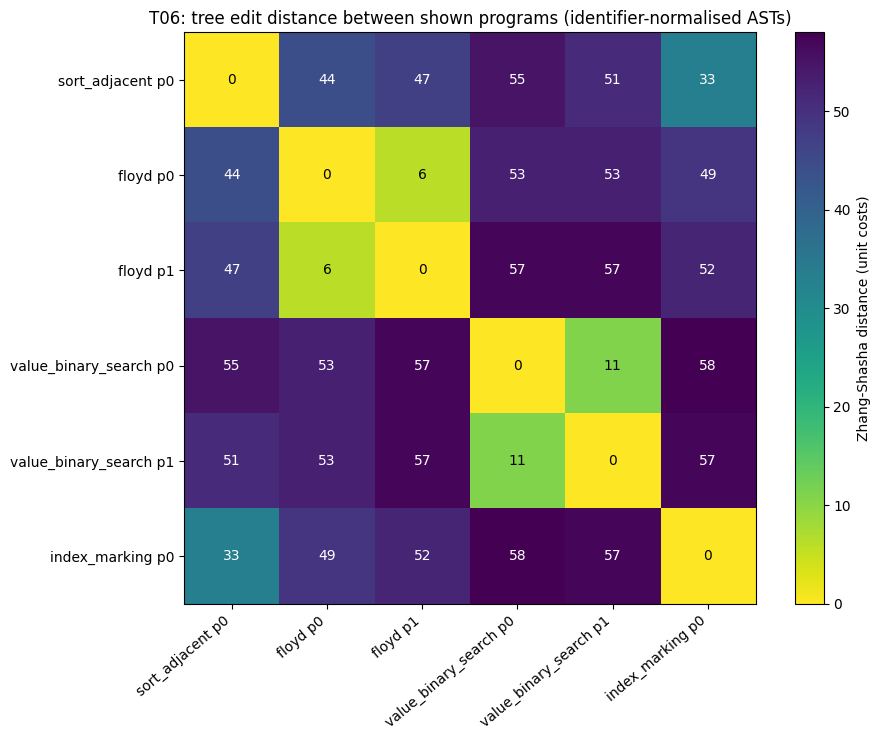

In [10]:
# ---- illustration: Zhang-Shasha distances between shown programs of different algorithms of one task ----
progs = []
for e in named_events:
    i = json.loads(e["input"])
    if i["task"] == ZSS_TASK:
        progs += [(i["banned_Y"], p["p_index"], p["code"]) for p in e["metadata_shown_programs"][:2]]
progs = progs[:N_ZSS_PROGRAMS]


def preorder(z):  # notebook helper: the node labels of a zss tree in pre-order
    yield z.label
    for ch in z.children:
        yield from preorder(ch)


tree0 = normalised_tree(progs[0][2])
print(f"shown program {progs[0][0]} p{progs[0][1]}:\n{progs[0][2]}")
print(f"its identifier-normalised AST ({tree_size(tree0)} nodes), first 24 labels in pre-order:\n  "
      + "  ".join(list(preorder(tree0))[:24]))

t0 = time.time()
n_p = len(progs)
D = np.zeros((n_p, n_p))
for a in range(n_p):
    for b in range(a + 1, n_p):
        D[a, b] = D[b, a] = pair_distance((f"{a}|{b}", progs[a][2], progs[b][2]))[1]
print(f"\n{n_p * (n_p - 1) // 2} Zhang-Shasha pairs in {time.time() - t0:.1f} s")
labels = [f"{yy} p{pi}" for yy, pi, _ in progs]
fig, ax = plt.subplots(figsize=(1.2 * n_p + 2.5, 1.0 * n_p + 1.5))
im = ax.imshow(D, cmap="viridis_r")
for a in range(n_p):
    for b in range(n_p):
        ax.text(b, a, f"{D[a, b]:.0f}", ha="center", va="center", color="black" if D[a, b] < D.max() / 2 else "white")
ax.set_xticks(range(n_p), labels, rotation=40, ha="right")
ax.set_yticks(range(n_p), labels)
ax.set_title(f"{ZSS_TASK}: tree edit distance between shown programs (identifier-normalised ASTs)")
fig.colorbar(im, ax=ax, label="Zhang-Shasha distance (unit costs)")
plt.tight_layout()
plt.show()

### 2c · From distances to the PROXIMITY forecast

`forecasts.proximity()` first takes, for each shown program, the median distance to each survivor's reference programs and picks the nearest survivor(s). It then weights each program by its share of the 50 samples.

The demo data carries the committed per-program medians, so the original aggregation step can rebuild the committed PROXIMITY forecast of every Y.

In [11]:
# ---- exposure/forecasts.py proximity(): the aggregation step, fed with the committed per-program median distances ----
def proximity_from_medians(per_program: list[dict], alloc: list[int]) -> dict:
    mix = Counter()
    for p, n_p in zip(per_program, alloc):
        med = p["median_zss"]  # survivor -> median Zhang-Shasha distance to its <= 20 forced reference programs
        best = min(med.values())
        near = sorted(j for j, v in med.items() if v == best)
        for j in near:
            mix[j] += n_p / N_PER_ARM / len(near)
    return dict(mix)


print(f"showcase {SHOW_KEY}: committed median distances per shown program")
for p in ex["metadata_proximity_per_program"]:
    print(f"  p{p['p_index']} (weight {p['weight']:.2f}): {p['median_zss']} -> nearest {p['nearest']}")
n_ok = 0
for e in named_events:
    pp = e["metadata_proximity_per_program"]
    got, want = proximity_from_medians(pp, allocation(len(pp))), e["metadata_forecasts"]["PROXIMITY"]
    n_ok += set(got) == set(want) and all(abs(got[k] - want[k]) < 1e-9 for k in want)
print(f"PROXIMITY re-aggregated from the committed medians == committed PROXIMITY forecast for {n_ok}/{len(named_events)} Y")

showcase ('T05', 'brute_force'): committed median distances per shown program
  p0 (weight 0.50): {'hash_map': 36.0, 'sort_two_pointers': 66.0, 'sort_binary_search': 122.0} -> nearest ['hash_map']
  p1 (weight 0.50): {'hash_map': 38.0, 'sort_two_pointers': 67.0, 'sort_binary_search': 122.0} -> nearest ['hash_map']
PROXIMITY re-aggregated from the committed medians == committed PROXIMITY forecast for 33/33 Y


## 3 · `stage1` (GPU): SUBTRACT-IN-CONTEXT and the persistent n-gram veto

SUBTRACT-IN-CONTEXT asks where the model would land if Y were simply *removed*, with no ban text at all. Stage 1 regenerated the COPY-twin prompt while a vLLM V1 per-request logits processor vetoed Y's distinctive token n-gram g*.

- **Choosing g\*.** A frozen rule picks an n-gram present in ≥ 80% of Y's reference programs, with the least collateral on other algorithms.
- **The veto.** Whenever the last n−1 generated tokens equal g*'s prefix, g*'s last token gets logit −∞. A 1-gram is banned at every step.
- **Further rounds.** If Y still re-emerged in ≥ 20% of attempts, the next round also vetoed the n-gram the re-emerging programs share, for at most 3 rounds.
- **The forecast.** The non-Y landing of the round used is the SUBTRACT forecast, committed in COMMIT #2 before any ban sample.

The cell below holds the n-gram helpers of `exposure/ngram.py` and the per-request veto logic `RequestVeto` of `exposure/veto.py`, verbatim. The vLLM adapter class that installs `RequestVeto` inside the engine is defined only when vLLM is installed; it is not needed on CPU.

In [12]:
# ---- exposure/ngram.py (the helpers used by the veto rounds and the smoke tests) ----
def ngram_set(ids: list[int], nmax: int = 6) -> set[tuple[int, ...]]:
    out: set[tuple[int, ...]] = set()
    n_ids = len(ids)
    for n in range(1, nmax + 1):
        for i in range(n_ids - n + 1):
            out.add(tuple(ids[i:i + n]))
    return out


def contains(ids: list[int], g: tuple[int, ...] | list[int]) -> bool:
    g = tuple(g)
    n = len(g)
    if n == 0 or n > len(ids):
        return False
    first = g[0]
    for i in range(len(ids) - n + 1):
        if ids[i] == first and tuple(ids[i:i + n]) == g:
            return True
    return False


def occurrences(ids: list[int], g: tuple[int, ...] | list[int]) -> list[int]:
    g = tuple(g)
    n = len(g)
    return [i for i in range(len(ids) - n + 1) if tuple(ids[i:i + n]) == g] if n else []


# ---- exposure/veto.py ----
class RequestVeto:
    """Per-request callable f(output_ids, logits_row) -> logits_row (modified in place)."""

    __slots__ = ("table", "lens", "_dev")

    def __init__(self, ngrams: list[list[int]]):
        table: dict[tuple[int, ...], set[int]] = {}
        for g in ngrams:
            g = tuple(int(x) for x in g)
            if g:
                table.setdefault(g[:-1], set()).add(g[-1])
        self.table = {k: torch.tensor(sorted(v), dtype=torch.long) for k, v in table.items()}
        self.lens = sorted({len(k) for k in table})
        self._dev = None

    def __call__(self, output_ids: list[int], logits: torch.Tensor) -> torch.Tensor:
        if self._dev is None or self._dev != logits.device:
            self.table = {k: v.to(logits.device) for k, v in self.table.items()}
            self._dev = logits.device
        n_out = len(output_ids)
        for length in self.lens:
            if length > n_out:
                break
            key = tuple(output_ids[n_out - length:]) if length else ()
            banned = self.table.get(key)
            if banned is not None:
                logits[banned] = float("-inf")
        return logits


if importlib.util.find_spec("vllm") is not None:  # notebook: the engine-side adapter needs vLLM (GPU runs only)
    from vllm import SamplingParams
    from vllm.v1.sample.logits_processor import AdapterLogitsProcessor

    class NgramVeto(AdapterLogitsProcessor):
        @classmethod
        def validate_params(cls, params: SamplingParams):
            ea = params.extra_args or {}
            v = ea.get("veto")
            if v is not None and not (isinstance(v, list) and all(isinstance(g, list) and g for g in v)):
                raise ValueError("extra_args['veto'] must be a list of non-empty token-id lists")

        def is_argmax_invariant(self) -> bool:
            return False

        def new_req_logits_processor(self, params: SamplingParams) -> Optional[RequestVeto]:
            ea = params.extra_args or {}
            v = ea.get("veto")
            if not v:
                return None
            return RequestVeto(v)
else:
    print("vLLM not installed: NgramVeto (the vLLM V1 AdapterLogitsProcessor that installs RequestVeto per request) "
          "is not defined; RequestVeto itself is what runs at every decoding step")

vLLM not installed: NgramVeto (the vLLM V1 AdapterLogitsProcessor that installs RequestVeto per request) is not defined; RequestVeto itself is what runs at every decoding step


### 3b · The stage-1 smoke tests, replayed on a toy model

Before trusting the veto, stage 1 ran three smoke tests on Qwen3-8B, each with 20 seeded twin pairs:

1. the vetoed n-gram never appears in the veto twin, though it does in the COPY twin;
2. an inert veto leaves the output token-for-token identical;
3. a COPY twin and its veto twin share every token up to the exact position where the COPY twin completes g*.

Test 3 works because vLLM samples by the exponential race: it draws one Exp(1) per vocabulary entry and takes the argmax of p/q. Two requests with the same seed therefore share their random stream token by token, and only a vetoed token can change the outcome.

`torch.multinomial` uses the same sampler, so the original `RequestVeto` can be checked against a seeded toy bigram "language model" standing in for Qwen3-8B.

In [13]:
# ---- toy replay of the three stage-1 smoke tests (sampling.smoke_tests ran them on Qwen3-8B with 20 twins) ----
BIGRAM = 3.0 * torch.randn(TOY_VOCAB, TOY_VOCAB, generator=torch.Generator().manual_seed(BASE_SEED))


def toy_generate(seed: int, veto: list[list[int]] | None = None, n_steps: int = N_TOY_STEPS) -> list[int]:
    """Seeded sampling at T = 1 from a toy bigram model; as in vLLM, the request's processor sees only generated ids."""
    gen = torch.Generator().manual_seed(seed)
    proc = RequestVeto(veto) if veto else None
    out: list[int] = []
    for _ in range(n_steps):
        logits = BIGRAM[out[-1] if out else 0].clone()  # token 0 stands in for the prompt
        if proc is not None:
            logits = proc(out, logits)
        # torch.multinomial (like vLLM's sampler) draws one Exp(1) per vocabulary entry and takes argmax(p / q):
        # two samples with one seed share their random stream token by token
        out.append(int(torch.multinomial(torch.softmax(logits, dim=-1), 1, generator=gen)))
    return out


twins = []
for i in range(N_TOY_TWINS):
    seed = seed_of(f"toy:twin:s{i}")
    copy_twin = toy_generate(seed)
    g_star = copy_twin[N_TOY_STEPS // 3: N_TOY_STEPS // 3 + 2]  # stand-in for Y's distinctive n-gram (a 2-gram)
    veto_twin = toy_generate(seed, veto=[g_star])
    seen = set(zip(copy_twin, copy_twin[1:]))
    a_, b_ = next((a_, b_) for a_ in range(TOY_VOCAB) for b_ in range(TOY_VOCAB) if (a_, b_) not in seen)
    inert_twin = toy_generate(seed, veto=[[a_, b_, 0]])  # a 3-gram whose prefix the COPY twin never produces
    first_div = next((k for k, (u, v) in enumerate(zip(copy_twin, veto_twin)) if u != v), None)
    twins.append({"copy": copy_twin, "veto": veto_twin, "g": g_star, "div": first_div,
                  "g_in_copy": contains(copy_twin, g_star), "g_in_veto": contains(veto_twin, g_star),
                  "inert_identical": inert_twin == copy_twin,
                  "consistent": first_div == occurrences(copy_twin, g_star)[0] + len(g_star) - 1})

tw = twins[0]
print(f"twin pair 0: vetoed g* = {tw['g']}; the COPY twin first completes it at position {tw['div']} (bracketed)")
print("  COPY twin:", " ".join(f"[{x}]" if k == tw["div"] else str(x) for k, x in enumerate(tw["copy"])))
print("  VETO twin:", " ".join(f"[{x}]" if k == tw["div"] else str(x) for k, x in enumerate(tw["veto"])))
print(f"\ntoy replay over {N_TOY_TWINS} twin pairs:")
print(f"  vetoed n-gram present: COPY twin {sum(r['g_in_copy'] for r in twins)}/{N_TOY_TWINS}, "
      f"veto twin {sum(r['g_in_veto'] for r in twins)}/{N_TOY_TWINS}")
print(f"  inert veto output identical to the COPY twin: {sum(r['inert_identical'] for r in twins)}/{N_TOY_TWINS}")
print(f"  twins diverge exactly where the COPY twin completes g*: {sum(r['consistent'] for r in twins)}/{N_TOY_TWINS}")
st = data["metadata"]["smoke_tests"]
print(f"published GPU smoke tests (Qwen3-8B, {st['key']}, g* = {st['g_star_text']!r}): vetoed n-gram in "
      f"{st['veto_occurrences']}/20 veto samples vs {st['copy_occurrences']}/20 COPY samples; inert veto identical "
      f"{st['inert_veto']['identical_to_plain']}/20; twin divergence at the vetoed position "
      f"{st['twin_diagnostic']['n_consistent']}/{st['twin_diagnostic']['n']}")

twin pair 0: vetoed g* = [1, 12]; the COPY twin first completes it at position 11 (bracketed)
  COPY twin: 13 10 15 3 5 13 9 15 4 4 1 [12] 5 13 8 2 3 4 1 12 3 12 3 1 0 13 13 4 4 9
  VETO twin: 13 10 15 3 5 13 9 15 4 4 1 [0] 11 0 11 11 11 9 15 12 3 12 3 1 0 13 13 4 4 9

toy replay over 20 twin pairs:
  vetoed n-gram present: COPY twin 20/20, veto twin 0/20
  inert veto output identical to the COPY twin: 20/20
  twins diverge exactly where the COPY twin completes g*: 20/20
published GPU smoke tests (Qwen3-8B, T03:size_k_heap, g* = 'ush'): vetoed n-gram in 0/20 veto samples vs 20/20 COPY samples; inert veto identical 20/20; twin divergence at the vetoed position 20/20


### 3c · What stage 1 and stage 2 produced

- **`stage1`** also ran a bf16 baseline check (the context-free task prompt, 20 samples per task). It confirmed every committed default.
- **`commit2`** hash-chained SUBTRACT-IN-CONTEXT, the veto rounds and the COPY-twin summary.
- **`stage2`** then drew the bans:
  - NAMED and UNNAMED, 3,300 programs;
  - the descriptive W1–W4 template arm, 760 programs.

  Every ban sample is timestamped after COMMIT #2.

The cell below reads the committed stage-1 records that ship with the events. They hold the key diagnostic: the veto rarely removed Y.

In [14]:
# ---- what stage 1 produced, read from the committed records in the demo data ----
subs = {f"{json.loads(e['input'])['task']}:{json.loads(e['input'])['banned_Y']}": e["metadata_subtract_in_context"]
        for e in named_events}
ng = ex["metadata_ngram"]
print(f"showcase {SHOW_KEY}: round-1 g* = {ng['decoded']!r} ({ng['n']}-gram, present in {ng['presence']:.0%} of the "
      f"reference programs of Y, collateral {ng['collateral']:.2f}); SUBTRACT record: {ex['metadata_subtract_in_context']}")
print(f"\nSUBTRACT-IN-CONTEXT is defined (>= {MIN_NONY_SUBTRACT} non-Y attempts in some veto round) for "
      f"{sum(not s['undefined'] for s in subs.values())}/{len(subs)} Y:")
for k, s in subs.items():
    if not s["undefined"]:
        print(f"  {k:<24} round {s['round_used']}: {s['distribution']}")
print(f"Y still re-emerges in >= {REEMERGE_MIN:.0%} of attempts after {MAX_ROUNDS} veto rounds ('not carried by a small "
      f"set of surface tokens') for {sum(s['not_carried_by_surface_tokens'] for s in subs.values())}/{len(subs)} Y")
base = data["metadata"]["bf16_baseline_check"]
print("\nbf16 baseline check (context-free task prompt, 20 samples per task) - share of the committed default:")
print("  " + ", ".join(f"{t_}: {v['default']} {v['default_share']:.2f}" for t_, v in base.items()))

showcase ('T05', 'brute_force'): round-1 g* = '(i +' (2-gram, present in 100% of the reference programs of Y, collateral 0.00); SUBTRACT record: {'distribution': {'hash_map': 1.0}, 'counts': {'hash_map': 30}, 'undefined': False, 'round_used': 3, 'n_nonY': 30, 'not_carried_by_surface_tokens': False}

SUBTRACT-IN-CONTEXT is defined (>= 20 non-Y attempts in some veto round) for 4/33 Y:
  T03:median_of_medians    round 3: {'quickselect': 0.95, 'counting_sort': 0.05}
  T05:brute_force          round 3: {'hash_map': 1.0}
  T10:label_propagation    round 2: {'union_find': 0.96, 'dfs': 0.02, 'bfs': 0.02}
  R6:exponential_search    round 3: {'binary_search': 0.975, 'other': 0.025}
Y still re-emerges in >= 20% of attempts after 3 veto rounds ('not carried by a small set of surface tokens') for 25/33 Y

bf16 baseline check (context-free task prompt, 20 samples per task) - share of the committed default:
  T03: full_sort 1.00, T04: naive 1.00, T06: hash_set 1.00, T05: hash_map 1.00, T10: union_fin

## 4 · `analyze`: the frozen C1 analysis code (`analysis/c1.py`, hash-committed in COMMIT #1)

**Scoring one event.** S is the survivor set and the landing is the label counts of the non-Y attempts. Each family's raw forecast f is restricted to S + `other` and smoothed:

  q = 0.95·f + 0.05·Uniform(S),  p = 0.98·q + 0.02·δ_other.

The family's **mean log score** is the mean of ln p(label) over the non-Y attempts. Its **top-1** is the argmax of f (ties are kept), and **hit** = |top-1 ∩ modal landing| / (|top-1|·|modal|).

**Which events count:**
- an event is **gated** when avoidance ≥ 0.5 and it has ≥ 20 non-Y attempts;
- it is **disagreeing** when the four top-1 sets are not all equal.

**Advance rule.** On each gated disagreeing event, a family **wins** if its log score beats every other family's by ≥ 0.10 nats. A family **advances** with ≥ 3 wins.

**Tests.** Four two-sided paired Wilcoxon signed-rank tests run on the per-event log-score differences between a ban-free family (SUBTRACT, LADDER) and a substitution family (ASSOCIATE, PROXIMITY). They are Holm-corrected and come with task-cluster bootstrap 95% CIs.

**Verdict and extras.** `branch()` combines the rule and the tests into the verdict. The module also holds C1-exposure and three placebos.

The cell is the file verbatim, with two exceptions. The bootstrap and null sizes come from the config cell. At the end, the definitions are collected under the name `c1`, which is how `from analysis import c1` exposed them in the repository.

In [15]:
"""Frozen C1 analysis code (hash-committed in COMMIT #1 before any generation).

Scoring (plan 4.3): survivor set S = catalogue minus Y; raw forecast f over S plus 'other';
  q = 0.95 f + 0.05 Uniform(S);  p = 0.98 q + 0.02 delta_other;  logscore_F = mean over non-Y attempts of ln p_F(label);
  top1_F = argmax of raw f (ties keep all tied labels); an undefined forecast is Uniform(S).
Event: modal label = argmax of the non-Y landing; hit_F = |top1_F & modal| / (|top1_F| |modal|);
  disagreeing = the four top-1 sets are not all equal; gate_pass = avoidance >= 0.5 and n_nonY >= 20.
Advance rule (4.4): on each gated disagreeing event, F wins if logscore_F - max_{G != F} logscore_G >= 0.10;
  F advances if it wins >= 3 events.  With >= 10 such events: four two-sided paired Wilcoxon signed-rank tests
  (zeros dropped = zero_method 'wilcox'; exact for n <= 25) on per-event log-score differences
  SUBTRACT-ASSOCIATE, SUBTRACT-PROXIMITY, LADDER-ASSOCIATE, LADDER-PROXIMITY, Holm-corrected over the 4, with
  task-cluster bootstrap 95% CIs (10,000 resamples) of the mean differences.
C1-exposure (4.5): JS (base 2) between NAMED and veto non-Y landings against a cluster-bootstrap null
  (clusters = shown program x arm, at the observed sizes; 2,000 pairs).
"""

FAMILIES = ["SUBTRACT", "LADDER", "ASSOCIATE", "PROXIMITY"]
BAN_FREE = ("SUBTRACT", "LADDER")
SUBSTITUTION = ("ASSOCIATE", "PROXIMITY")
TEST_PAIRS = [("SUBTRACT", "ASSOCIATE"), ("SUBTRACT", "PROXIMITY"), ("LADDER", "ASSOCIATE"), ("LADDER", "PROXIMITY")]
OTHER = "other"
W_FORECAST = 0.95
W_OTHER = 0.02
WIN_MARGIN = 0.10
MIN_WINS = 3
MIN_EVENTS_TESTS = 10
MIN_EVENTS_RULE = 3
GATE_AVOID = 0.5
GATE_NONY = 20
ALPHA = 0.05
N_BOOT = C1_N_BOOT  # config cell (original: 10_000)
N_NULL = C1_N_NULL  # config cell (original: 2_000)
EXACT_MAX_N = 25


# ------------------------------------------------------------------------------------------------- distributions
def normalise_label(label: str, y: str, survivors: list[str]) -> str | None:
    """None for 'invalid' (not an attempt); Y and survivors unchanged; anything else ('other', 'unknown') -> 'other'."""
    if label == "invalid":
        return None
    if label == y or label in survivors:
        return label
    return OTHER


def clean_forecast(f: dict | None, survivors: list[str]) -> dict:
    """Restrict a raw forecast to S + 'other' and renormalise; undefined / empty -> Uniform(S)."""
    s = list(survivors)
    if f:
        g = {k: float(v) for k, v in f.items() if (k in s or k == OTHER) and v > 0}
        tot = sum(g.values())
        if tot > 0:
            return {k: v / tot for k, v in g.items()}
    return {k: 1.0 / len(s) for k in s}


def smooth(f: dict | None, survivors: list[str]) -> dict:
    s = list(survivors)
    k = len(s)
    g = clean_forecast(f, s)
    q = {x: W_FORECAST * g.get(x, 0.0) + (1.0 - W_FORECAST) / k for x in s}
    q[OTHER] = W_FORECAST * g.get(OTHER, 0.0)
    p = {x: (1.0 - W_OTHER) * v for x, v in q.items()}
    p[OTHER] += W_OTHER
    return p


def log_score(f: dict | None, survivors: list[str], counts: dict) -> float:
    """Mean ln p(label) over the non-Y attempts given as label counts (labels already normalised)."""
    p = smooth(f, survivors)
    n = sum(counts.values())
    if n == 0:
        return float("nan")
    return sum(c * math.log(p[lab]) for lab, c in counts.items()) / n


def top1(f: dict | None, survivors: list[str]) -> list[str]:
    g = clean_forecast(f, survivors)
    mx = max(g.values())
    return sorted(k for k, v in g.items() if abs(v - mx) < 1e-12)


def modal(counts: dict, restrict: list[str] | None = None) -> list[str]:
    c = {k: v for k, v in counts.items() if v > 0 and (restrict is None or k in restrict)}
    if not c:
        return []
    mx = max(c.values())
    return sorted(k for k, v in c.items() if v == mx)


def hit(t1: list[str], mod: list[str]) -> float:
    if not t1 or not mod:
        return 0.0
    return len(set(t1) & set(mod)) / (len(t1) * len(mod))


def is_disagreeing(top1s: dict[str, list[str]]) -> bool:
    return len({tuple(sorted(v)) for v in top1s.values()}) > 1


def js_divergence(a: dict, b: dict) -> float:
    """Jensen-Shannon divergence, base 2, between two count / probability dicts."""
    keys = sorted(set(a) | set(b))
    pa = np.array([a.get(k, 0.0) for k in keys], dtype=float)
    pb = np.array([b.get(k, 0.0) for k in keys], dtype=float)
    if pa.sum() == 0 or pb.sum() == 0:
        return float("nan")
    pa, pb = pa / pa.sum(), pb / pb.sum()
    m = 0.5 * (pa + pb)

    def kl(x, y):
        nz = x > 0
        return float(np.sum(x[nz] * np.log2(x[nz] / y[nz])))

    return 0.5 * kl(pa, m) + 0.5 * kl(pb, m)


def hill_shannon(counts: dict) -> float:
    n = sum(counts.values())
    if n == 0:
        return float("nan")
    return math.exp(-sum((c / n) * math.log(c / n) for c in counts.values() if c > 0))


# ------------------------------------------------------------------------------------------------------ events
def gate(avoidance: float, n_nony: int) -> bool:
    return (not math.isnan(avoidance)) and avoidance >= GATE_AVOID and n_nony >= GATE_NONY


def score_event(survivors: list[str], landing: dict, forecasts: dict[str, dict | None]) -> dict:
    """landing: normalised non-Y label counts; forecasts: family -> raw distribution (None = undefined)."""
    mod = modal(landing)
    t1 = {f: top1(forecasts.get(f), survivors) for f in FAMILIES}
    return {"modal": mod,
            "top1": t1,
            "logscore": {f: log_score(forecasts.get(f), survivors, landing) for f in FAMILIES},
            "hit": {f: hit(t1[f], mod) for f in FAMILIES},
            "disagreeing": is_disagreeing(t1),
            "unaimed": bool(mod) and all(not (set(mod) & set(t1[f])) for f in FAMILIES)}


# ------------------------------------------------------------------------------------------------ advance rule
def advance_rule(events: list[dict], families: list[str] = FAMILIES) -> dict:
    wins = Counter()
    winners = []
    for ev in events:
        ls = ev["logscore"]
        w = None
        for f in families:
            others = [ls[g] for g in families if g != f]
            if ls[f] - max(others) >= WIN_MARGIN:
                wins[f] += 1
                w = f
        winners.append(w)
    adv = [f for f in families if wins[f] >= MIN_WINS]
    return {"n_events": len(events), "wins": {f: wins[f] for f in families}, "advancing": adv, "winners": winners}


def holm(pvals: list[float]) -> list[float]:
    m = len(pvals)
    order = sorted(range(m), key=lambda i: pvals[i])
    adj = [0.0] * m
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * pvals[i]))
        adj[i] = running
    return adj


def wilcoxon_two_sided(d: list[float]) -> dict:
    nz = [x for x in d if x != 0]
    if not nz:
        return {"n": len(d), "n_nonzero": 0, "statistic": None, "p": 1.0, "method": "all-zero"}
    method = "exact" if len(nz) <= EXACT_MAX_N else "asymptotic"
    r = wilcoxon(nz, zero_method="wilcox", alternative="two-sided", method=method)
    return {"n": len(d), "n_nonzero": len(nz), "statistic": float(r.statistic), "p": float(r.pvalue), "method": method}


def cluster_bootstrap_mean(values: list[float], clusters: list[str], n_boot: int = N_BOOT, seed: int = 0) -> list[float]:
    """Percentile 95% CI of the mean, resampling clusters (tasks) with replacement."""
    by: dict[str, list[float]] = {}
    for v, c in zip(values, clusters):
        by.setdefault(c, []).append(v)
    keys = sorted(by)
    rng = random.Random(seed)
    means = []
    for _ in range(n_boot):
        vals = []
        for _k in keys:
            vals.extend(by[keys[rng.randrange(len(keys))]])
        means.append(sum(vals) / len(vals))
    return [float(np.quantile(means, 0.025)), float(np.quantile(means, 0.975))]


def paired_tests(events: list[dict], n_boot: int = N_BOOT, seed: int = 0) -> dict:
    if len(events) < MIN_EVENTS_TESTS:
        return {"run": False, "reason": f"{len(events)} < {MIN_EVENTS_TESTS} gated disagreeing events"}
    out = []
    for a, b in TEST_PAIRS:
        d = [ev["logscore"][a] - ev["logscore"][b] for ev in events]
        w = wilcoxon_two_sided(d)
        ci = cluster_bootstrap_mean(d, [ev["task"] for ev in events], n_boot=n_boot, seed=seed)
        out.append({"pair": f"{a}-{b}", "mean_diff": float(np.mean(d)), "median_diff": float(np.median(d)),
                    "ci95_task_cluster": ci, **w})
    adj = holm([r["p"] for r in out])
    for r, p in zip(out, adj):
        r["p_holm"] = p
        r["significant"] = p < ALPHA
        r["favours"] = (r["pair"].split("-")[0] if r["mean_diff"] > 0 else r["pair"].split("-")[1]) if r["significant"] else None
    return {"run": True, "tests": out}


def branch(rule: dict, tests: dict, unaimed_share: float, n_events: int) -> str:
    if n_events < MIN_EVENTS_RULE:
        return "UNDETERMINED"
    adv = set(rule["advancing"])
    adv_bf, adv_sub = adv & set(BAN_FREE), adv & set(SUBSTITUTION)
    fav = {r["favours"] for r in tests.get("tests", []) if r.get("significant")} if tests.get("run") else set()
    sig_bf, sig_sub = bool(fav & set(BAN_FREE)), bool(fav & set(SUBSTITUTION))
    if adv_bf and adv_sub:
        return "MIXED"
    if adv_bf and not sig_sub:
        return "SUBTRACTION/LADDER (" + "+".join(sorted(adv_bf)) + ")"
    if adv_sub and not sig_bf:
        return "SUBSTITUTION (" + "+".join(sorted(adv_sub)) + ")"
    if adv_bf or adv_sub:
        return "MIXED (advance contradicted by a Holm-significant test)"
    if unaimed_share >= 0.5:
        return "X-SPECIFIC BUT UNAIMED"
    return "NO FAMILY ADVANCES"


def run_c1(events: list[dict], n_boot: int = N_BOOT, seed: int = 0) -> dict:
    """events: dicts with task, gate_pass, disagreeing, logscore, unaimed.  Primary set = gated disagreeing."""
    sel = [e for e in events if e["gate_pass"] and e["disagreeing"]]
    rule = advance_rule(sel)
    tests = paired_tests(sel, n_boot=n_boot, seed=seed)
    unaimed = (sum(e["unaimed"] for e in sel) / len(sel)) if sel else float("nan")
    margins = []
    for e in sel:
        ls = e["logscore"]
        best = max(FAMILIES, key=lambda f: ls[f])
        margins.append({"Y": e.get("Y"), "task": e["task"], "best": best,
                        "margin": ls[best] - max(ls[g] for g in FAMILIES if g != best)})
    return {"n_events_total": len(events), "n_gated": sum(e["gate_pass"] for e in events),
            "n_gated_disagreeing": len(sel), "rule": rule, "tests": tests, "unaimed_share": unaimed,
            "branch": branch(rule, tests, unaimed if not math.isnan(unaimed) else 0.0, len(sel)),
            "margins": margins}


# ------------------------------------------------------------------------------------------------- C1-exposure
def js_null(clusters_a: list[list[str]], clusters_b: list[list[str]], n_null: int = N_NULL, seed: int = 0) -> dict:
    """Cluster-bootstrap null of JS(A, B): pool the clusters of both arms, draw |A| and |B| clusters with replacement.
    With fewer than 4 pooled clusters the null resamples programs instead (flagged)."""
    rng = random.Random(seed)
    pool = [c for c in clusters_a + clusters_b if c]
    level = "cluster"
    if len(pool) < 4:
        level = "program"
        progs = [x for c in pool for x in c]
        na, nb = sum(len(c) for c in clusters_a), sum(len(c) for c in clusters_b)
        vals = []
        for _ in range(n_null):
            a = Counter(progs[rng.randrange(len(progs))] for _ in range(na))
            b = Counter(progs[rng.randrange(len(progs))] for _ in range(nb))
            vals.append(js_divergence(a, b))
    else:
        na, nb = len([c for c in clusters_a if c]), len([c for c in clusters_b if c])
        vals = []
        for _ in range(n_null):
            a, b = Counter(), Counter()
            for _k in range(na):
                a.update(pool[rng.randrange(len(pool))])
            for _k in range(nb):
                b.update(pool[rng.randrange(len(pool))])
            vals.append(js_divergence(a, b))
    vals = [v for v in vals if not math.isnan(v)]
    return {"q95": float(np.quantile(vals, 0.95)) if vals else float("nan"), "level": level, "n": len(vals)}


def c1_exposure(items: list[dict], n_null: int = N_NULL, seed: int = 0) -> dict:
    """items: one per gated NAMED event with keys Y, task, survivors, coveto (modes), associate_top1, subtract_dist,
    proximity_top1, default, named_clusters / veto_clusters (lists of per-shown-program non-Y label lists)."""
    rows = []
    for it in items:
        s = it["survivors"]
        sub_mod = modal({k: v for k, v in (it["subtract_dist"] or {}).items() if k in s})
        assoc = it["associate_top1"]
        if not assoc or (set(assoc) & set(sub_mod)):
            continue  # the associate does not differ from SUBTRACT's modal survivor
        if set(assoc) & set(it["coveto"]) or it["default"] in it["coveto"]:
            continue
        allowed = [x for x in s if x not in it["coveto"]]
        a = Counter(x for c in it["named_clusters"] for x in c)
        b = Counter(x for c in it["veto_clusters"] for x in c)
        ma, mb = modal(a, allowed), modal(b, allowed)
        agree = bool(set(ma) & set(mb))
        js = js_divergence(a, b)
        nul = js_null(it["named_clusters"], it["veto_clusters"], n_null=n_null, seed=seed)
        disc = bool(set(ma) & (set(assoc) | set(it["proximity_top1"]))) and not bool(set(mb) & (set(assoc) | set(it["proximity_top1"])))
        rows.append({"task": it["task"], "Y": it["Y"], "named_modal": ma, "veto_modal": mb, "agree": agree, "js": js,
                     "js_null_q95": nul["q95"], "null_level": nul["level"], "js_consistent": js <= nul["q95"],
                     "disconfirming": disc, "associate": assoc, "subtract_modal": sub_mod})
    n = len(rows)
    if n == 0:
        return {"n_events": 0, "verdict": "EMPTY", "rows": []}
    ag = sum(r["agree"] for r in rows) / n
    di = sum(r["disconfirming"] for r in rows) / n
    if ag >= 2 / 3 and di >= 1 / 3:
        verdict = "CONFIRM+DISCONFIRM (mixed)"
    elif ag >= 2 / 3:
        verdict = "CONFIRM"
    elif di >= 1 / 3:
        verdict = "DISCONFIRM"
    else:
        verdict = "NEITHER"
    return {"n_events": n, "agreement_share": ag, "disconfirm_share": di,
            "js_consistent_share": sum(r["js_consistent"] for r in rows) / n, "verdict": verdict, "rows": rows}


# ---------------------------------------------------------------------------------------------------- placebos
def rescore(events: list[dict], new_forecasts: list[dict]) -> list[dict]:
    out = []
    for ev, fc in zip(events, new_forecasts):
        sc = score_event(ev["survivors"], ev["landing_counts_norm"], fc)
        out.append({**ev, **sc, "forecasts": fc})
    return out


def placebo_rotation(events: list[dict]) -> dict:
    """Rotate every family's forecast across Y within each task (event i gets event i+1's forecasts)."""
    by: dict[str, list[int]] = {}
    for i, ev in enumerate(events):
        by.setdefault(ev["task"], []).append(i)
    new = [None] * len(events)
    skipped = []
    for t, idx in by.items():
        if len(idx) < 2:
            skipped.append(t)
            for i in idx:
                new[i] = None
            continue
        for k, i in enumerate(idx):
            new[i] = events[idx[(k + 1) % len(idx)]]["forecasts"]
    keep = [i for i in range(len(events)) if new[i] is not None]
    res = run_c1(rescore([events[i] for i in keep], [new[i] for i in keep]), n_boot=N_BOOT_SECONDARY)  # config (original: 2000)
    return {"skipped_single_event_tasks": skipped, "n_events": len(keep), "advancing": res["rule"]["advancing"],
            "wins": res["rule"]["wins"], "branch": res["branch"], "n_gated_disagreeing": res["n_gated_disagreeing"]}


def placebo_permutation(events: list[dict], n_draws: int = 200, seed: int = 0) -> dict:
    """Relabel each event's survivors by a random permutation (same permutation for all four families)."""
    rng = random.Random(seed)
    adv_any, counts = 0, Counter()
    for _ in range(n_draws):
        fcs = []
        for ev in events:
            s = list(ev["survivors"])
            perm = s[:]
            rng.shuffle(perm)
            mp = dict(zip(s, perm))
            fcs.append({f: ({mp.get(k, k): v for k, v in (fc or {}).items()} if fc else None)
                        for f, fc in ev["forecasts"].items()})
        sc = rescore(events, fcs)
        sel = [e for e in sc if e["gate_pass"] and e["disagreeing"]]
        r = advance_rule(sel)
        adv_any += bool(r["advancing"])
        counts.update(r["advancing"])
    return {"n_draws": n_draws, "share_any_family_advances": adv_any / n_draws,
            "share_by_family": {f: counts[f] / n_draws for f in FAMILIES}}


# notebook glue: the repo imports this file as `from analysis import c1`, and events.py, report.py and figures.py call
# it as c1.<name>; collect the definitions under that name so their code runs unchanged
c1 = SimpleNamespace(**{k: v for k, v in globals().items() if not k.startswith("__")})

## 5 · Event assembly (`analysis/events.py`, frozen)

- `arm_stats` turns the labelled programs of one (Y, arm) into the statistics everything else uses: avoidance, non-Y landing counts, correct-only counts, default share and per-shown-program landings.
- `build_events` scores every (Y, NAMED or UNNAMED) event with `c1.score_event` and applies the gate.
- `sensitivities` re-runs C1 under the pre-registered variations.
- `exposure_items` collects the C1-exposure inputs.

The file is copied verbatim, and its functions are gathered under `EV`, the name `exposure/report.py` imports them as.

In [16]:
"""Frozen event assembly (hash-committed in COMMIT #1): per-(Y, arm) statistics, exposure events, the primary C1 run
and its pre-registered sensitivities, and the C1-exposure inputs.  Pure functions over per-sample rows."""

ARMS_EVENT = {"named": "exposure_named", "unnamed": "exposure_unnamed"}


def wilson(k: int, n: int, z: float = 1.959964) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return [max(0.0, c - h), min(1.0, c + h)]


def arm_stats(rows: list[dict], y: str, survivors: list[str], default: str) -> dict:
    """rows: samples of one (Y, arm[, round]).  Labels: mode ids, 'other', 'unknown' or 'invalid'."""
    n = len(rows)
    raw = Counter(r["label"] for r in rows)
    att = [r for r in rows if r["label"] != "invalid"]
    n_att = len(att)
    n_y = sum(1 for r in att if r["label"] == y)
    non = [r for r in att if r["label"] != y]
    land = Counter(c1.normalise_label(r["label"], y, survivors) for r in non)
    land_c = Counter(c1.normalise_label(r["label"], y, survivors) for r in non if r.get("passed"))
    avoid = 1 - n_y / n_att if n_att else float("nan")
    per_p = defaultdict(Counter)
    for r in non:
        per_p[r.get("p_index")][c1.normalise_label(r["label"], y, survivors)] += 1
    return {"n_programs": n, "label_counts": dict(raw), "n_invalid": raw.get("invalid", 0), "n_attempts": n_att,
            "n_Y": n_y, "Y_share": n_y / n_att if n_att else float("nan"), "Y_share_ci95": wilson(n_y, n_att),
            "avoidance": avoid, "avoidance_ci95": wilson(n_att - n_y, n_att), "n_nonY": len(non),
            "landing_counts": dict(land), "correct_counts": dict(land_c),
            "other_share": land.get(c1.OTHER, 0) / len(non) if non else float("nan"),
            "pass_rate": sum(1 for r in rows if r.get("passed")) / n if n else float("nan"),
            "pass_rate_attempts": sum(1 for r in att if r.get("passed")) / n_att if n_att else float("nan"),
            "hill_cc": c1.hill_shannon(land_c),
            "default_share": sum(1 for r in att if r["label"] == default) / n_att if n_att else float("nan"),
            "n_default": sum(1 for r in att if r["label"] == default),
            "modal_nonY": c1.modal(dict(land)),
            "landing_by_program": {str(k): dict(v) for k, v in sorted(per_p.items(), key=lambda kv: str(kv[0]))}}


def subtract_top1(dist: dict | None, survivors: list[str]) -> dict | None:
    if not dist:
        return None
    s = {k: v for k, v in dist.items() if k in survivors and v > 0}
    if not s:
        return None
    mx = max(s.values())
    top = [k for k, v in s.items() if v == mx]
    return {k: 1.0 / len(top) for k in top}


def build_events(samples: list[dict], meta: dict, forecasts: dict, arms=("named", "unnamed"),
                 model: str = "Qwen/Qwen3-8B", commit_sha256: str | None = None,
                 landing_key: str = "landing_counts") -> list[dict]:
    """meta[key] = {task, Y, default, survivors, associate, n_pY, veto_round_used, coveto_modes, flags, priority};
    forecasts[key] = {SUBTRACT, LADDER, ASSOCIATE, PROXIMITY} raw distributions (None = undefined)."""
    by = defaultdict(list)
    for r in samples:
        by[(r["task"], r["Y"], r["arm"])].append(r)
    events = []
    for key, m in meta.items():
        for arm in arms:
            rows = by.get((m["task"], m["Y"], arm), [])
            if not rows:
                continue
            st = arm_stats(rows, m["Y"], m["survivors"], m["default"])
            land = st[landing_key]
            fc = forecasts[key]
            sc = c1.score_event(m["survivors"], land, fc)
            gate_pass = c1.gate(st["avoidance"], st["n_nonY"])
            if landing_key == "correct_counts":
                gate_pass = gate_pass and sum(land.values()) > 0
            events.append({"model": model, "task": m["task"], "event_type": ARMS_EVENT[arm], "banned": m["Y"],
                           "Y": m["Y"], "arm": arm, "default": m["default"], "associate": m["associate"],
                           "survivors": m["survivors"], "n_attempts": st["n_attempts"], "avoidance": st["avoidance"],
                           "avoidance_ci95": st["avoidance_ci95"], "n_nonY": st["n_nonY"], "gate_pass": gate_pass,
                           "landing_counts": st["landing_counts"], "correct_counts": st["correct_counts"],
                           "landing_counts_norm": land, "other_share": st["other_share"],
                           "forecasts": fc, "top1": sc["top1"], "logscore": sc["logscore"], "hit": sc["hit"],
                           "modal": sc["modal"], "disagreeing": sc["disagreeing"], "unaimed": sc["unaimed"],
                           "commit_sha256": commit_sha256, "n_pY": m["n_pY"], "veto_round_used": m["veto_round_used"],
                           "coveto": m["coveto_modes"], "flags": m["flags"], "priority": m["priority"],
                           "hill_cc": st["hill_cc"], "pass_rate": st["pass_rate"], "default_share": st["default_share"]})
    return events


def sensitivities(events_named: list[dict], forecasts: dict, prox_token: dict, n_boot: int = 2000) -> dict:
    """Pre-registered C1 sensitivities on the NAMED events."""
    out = {}
    ev2 = []
    for e in events_named:
        fc = dict(e["forecasts"])
        fc["SUBTRACT"] = subtract_top1(fc.get("SUBTRACT"), e["survivors"])
        ev2.append(fc)
    out["subtract_top1"] = _summ(c1.run_c1(c1.rescore(events_named, ev2), n_boot=n_boot))
    pair = {}
    for a, b in c1.TEST_PAIRS:
        sel = [e for e in events_named if e["gate_pass"] and set(e["top1"][a]) != set(e["top1"][b])]
        d = [e["logscore"][a] - e["logscore"][b] for e in sel]
        w = c1.wilcoxon_two_sided(d) if d else {"p": None, "n_nonzero": 0}
        wins_a = sum(1 for x in d if x >= c1.WIN_MARGIN)
        wins_b = sum(1 for x in d if x <= -c1.WIN_MARGIN)
        pair[f"{a}-{b}"] = {"n_events": len(sel), "mean_diff": (sum(d) / len(d)) if d else None, "p_uncorrected": w.get("p"),
                            "wins": {a: wins_a, b: wins_b}}
    out["per_pair_disagreeing"] = pair
    out["exclude_coveto_survivor"] = _summ(c1.run_c1([e for e in events_named if not e["coveto"]], n_boot=n_boot))
    out["priority_only"] = _summ(c1.run_c1([e for e in events_named if e["priority"]], n_boot=n_boot))
    ev_tok = []
    for e in events_named:
        fc = dict(e["forecasts"])
        fc["PROXIMITY"] = prox_token.get(f"{e['task']}:{e['Y']}")
        ev_tok.append(fc)
    out["token_distance_proximity"] = _summ(c1.run_c1(c1.rescore(events_named, ev_tok), n_boot=n_boot))
    return out


def correct_only(samples: list[dict], meta: dict, forecasts: dict, commit_sha256: str | None, n_boot: int = 2000) -> dict:
    ev = build_events(samples, meta, forecasts, arms=("named",), commit_sha256=commit_sha256,
                      landing_key="correct_counts")
    return _summ(c1.run_c1(ev, n_boot=n_boot))


def _summ(res: dict) -> dict:
    return {"n_gated_disagreeing": res["n_gated_disagreeing"], "n_gated": res["n_gated"], "wins": res["rule"]["wins"],
            "advancing": res["rule"]["advancing"], "branch": res["branch"], "unaimed_share": res["unaimed_share"],
            "tests": res["tests"]}


def exposure_items(events_named: list[dict], samples: list[dict], veto_round_used: dict) -> list[dict]:
    """C1-exposure inputs: per gated NAMED event, the per-shown-program non-Y labels under NAMED and under the veto
    round whose landing defines SUBTRACT."""
    by = defaultdict(list)
    for r in samples:
        by[(r["task"], r["Y"], r["arm"], r.get("round") or 0)].append(r)
    items = []
    for e in events_named:
        if not e["gate_pass"]:
            continue
        key = f"{e['task']}:{e['Y']}"
        rnd = veto_round_used.get(key)
        if not rnd:
            continue

        def clusters(rows):
            cl = defaultdict(list)
            for r in rows:
                lab = c1.normalise_label(r["label"], e["Y"], e["survivors"])
                if lab is None or lab == e["Y"]:
                    continue
                cl[r.get("p_index")].append(lab)
            return [cl[k] for k in sorted(cl, key=str)]

        items.append({"task": e["task"], "Y": e["Y"], "survivors": e["survivors"], "coveto": e["coveto"],
                      "default": e["default"], "associate_top1": e["top1"]["ASSOCIATE"],
                      "subtract_dist": e["forecasts"].get("SUBTRACT"), "proximity_top1": e["top1"]["PROXIMITY"],
                      "named_clusters": clusters(by[(e["task"], e["Y"], "named", 0)]),
                      "veto_clusters": clusters(by[(e["task"], e["Y"], "veto", rnd)])})
    return items


# notebook glue: exposure/report.py imports this file as `from analysis import events as EV`
EV = SimpleNamespace(ARMS_EVENT=ARMS_EVENT, wilson=wilson, arm_stats=arm_stats, subtract_top1=subtract_top1,
                     build_events=build_events, sensitivities=sensitivities, correct_only=correct_only, _summ=_summ,
                     exposure_items=exposure_items)

## 6 · `analyze()` inputs, from the published data

In the artifact, `analyze()` (`exposure/report.py`) began by:

1. rebuilding `data/samples.jsonl` from the 10,600 generations and their labels;
2. computing every per-(Y, arm) table with `EV.arm_stats`;
3. reading the committed forecasts from `predictions/` (`meta_and_forecasts()`).

The demo data already carries the outputs of these steps. Every event has the committed forecasts and metadata, and each Y's NAMED event has its `EV.arm_stats` tables. Three functions therefore get a sample-free twin, identical to the original except for the lines marked `CHANGED`:

- `build_events` takes `st` from the arm table instead of recomputing it from rows;
- `exposure_items` and the NAMED-vs-UNNAMED report rebuild their per-shown-program label clusters from the table's `landing_by_program` counts.

The rebuilt events are then compared, field by field, with the published event rows.

In [17]:
# ---- exposure/report.py meta_and_forecasts(): the committed predictions, read from the events of mini_demo_data.json
#      instead of predictions/*.json (same keys and values) ----
def meta_and_forecasts():
    meta, fc, prox_tok, sub = {}, {}, {}, {}
    for e in EXAMPLES:
        if e["metadata_event_type"] != "exposure_named":  # one entry per Y
            continue
        inp = json.loads(e["input"])
        t, y = inp["task"], inp["banned_Y"]
        key = f"{t}:{y}"
        meta[key] = {"task": t, "Y": y, "default": e["metadata_default"], "survivors": e["metadata_survivors"],
                     "associate": e["metadata_associate"], "n_pY": e["metadata_n_pY"],
                     "veto_round_used": e["metadata_veto_round_used"], "coveto_modes": e["metadata_coveto"],
                     "flags": e["metadata_flags"], "priority": e["metadata_priority"]}
        fc[key] = e["metadata_forecasts"]  # {SUBTRACT, LADDER, ASSOCIATE, PROXIMITY} raw distributions (None = undefined)
        prox_tok[key] = e["metadata_proximity_token_distance"]
        sub[key] = e["metadata_subtract_in_context"]
    return meta, fc, prox_tok, sub


meta, fc, prox_tok, sub = meta_and_forecasts()
# = arm_table(samples, meta) of the artifact: EV.arm_stats over the 10,600 labelled programs, one table per (Y, arm)
arms = {f"{json.loads(e['input'])['task']}:{json.loads(e['input'])['banned_Y']}": e["metadata_arm_stats"]
        for e in EXAMPLES if e["metadata_event_type"] == "exposure_named"}


def build_events_from_arm_table(arm_table: dict, meta: dict, forecasts: dict, arms=("named", "unnamed"),
                                model: str = "Qwen/Qwen3-8B", commit_sha256: str | None = None,
                                landing_key: str = "landing_counts") -> list[dict]:
    """EV.build_events with st taken from the arm table instead of EV.arm_stats(rows); the CHANGED line is marked."""
    events = []
    for key, m in meta.items():
        for arm in arms:
            st = arm_table.get(key, {}).get(arm)  # CHANGED: was rows = by.get(...); st = arm_stats(rows, ...)
            if not st:
                continue
            land = st[landing_key]
            fc = forecasts[key]
            sc = c1.score_event(m["survivors"], land, fc)
            gate_pass = c1.gate(st["avoidance"], st["n_nonY"])
            if landing_key == "correct_counts":
                gate_pass = gate_pass and sum(land.values()) > 0
            events.append({"model": model, "task": m["task"], "event_type": EV.ARMS_EVENT[arm], "banned": m["Y"],
                           "Y": m["Y"], "arm": arm, "default": m["default"], "associate": m["associate"],
                           "survivors": m["survivors"], "n_attempts": st["n_attempts"], "avoidance": st["avoidance"],
                           "avoidance_ci95": st["avoidance_ci95"], "n_nonY": st["n_nonY"], "gate_pass": gate_pass,
                           "landing_counts": st["landing_counts"], "correct_counts": st["correct_counts"],
                           "landing_counts_norm": land, "other_share": st["other_share"],
                           "forecasts": fc, "top1": sc["top1"], "logscore": sc["logscore"], "hit": sc["hit"],
                           "modal": sc["modal"], "disagreeing": sc["disagreeing"], "unaimed": sc["unaimed"],
                           "commit_sha256": commit_sha256, "n_pY": m["n_pY"], "veto_round_used": m["veto_round_used"],
                           "coveto": m["coveto_modes"], "flags": m["flags"], "priority": m["priority"],
                           "hill_cc": st["hill_cc"], "pass_rate": st["pass_rate"], "default_share": st["default_share"]})
    return events


def clusters_from_arm_table(st: dict) -> list[list[str]]:
    """Per-shown-program lists of normalised non-Y labels, rebuilt from the arm table's landing_by_program (counts);
    replaces the clusters(rows) / cl(rows) helpers that grouped the per-sample rows by p_index."""
    lbp = st["landing_by_program"]
    return [[lab for lab, n in lbp[k].items() for _ in range(n)] for k in sorted(lbp, key=str)]


def exposure_items_from_arm_table(events_named: list[dict], arm_table: dict, veto_round_used: dict) -> list[dict]:
    """EV.exposure_items with the clusters rebuilt from the arm table; the CHANGED lines are marked."""
    items = []
    for e in events_named:
        if not e["gate_pass"]:
            continue
        key = f"{e['task']}:{e['Y']}"
        rnd = veto_round_used.get(key)
        if not rnd:
            continue
        items.append({"task": e["task"], "Y": e["Y"], "survivors": e["survivors"], "coveto": e["coveto"],
                      "default": e["default"], "associate_top1": e["top1"]["ASSOCIATE"],
                      "subtract_dist": e["forecasts"].get("SUBTRACT"), "proximity_top1": e["top1"]["PROXIMITY"],
                      "named_clusters": clusters_from_arm_table(arm_table[key]["named"]),         # CHANGED
                      "veto_clusters": clusters_from_arm_table(arm_table[key][f"veto_r{rnd}"])})  # CHANGED
    return items


# commit_sha("COMMIT2") read the last COMMIT2 line of commitments.log; its value ships with the published summary
c2 = data["metadata"]["published_summary"]["commit2_sha256"]
evs = build_events_from_arm_table(arms, meta, fc, arms=("named", "unnamed"), model=MODEL_ID, commit_sha256=c2)

# sanity check: the events rebuilt by the frozen scorer reproduce the published event rows field by field
pub = {(json.loads(e["input"])["task"], json.loads(e["input"])["banned_Y"], e["metadata_event_type"]): e for e in EXAMPLES}
n_same, max_dls = 0, 0.0
for e in evs:
    p = pub[(e["task"], e["Y"], e["event_type"])]
    n_same += (e["gate_pass"] == p["metadata_gate_pass"] and e["disagreeing"] == p["metadata_disagreeing"]
               and e["landing_counts"] == p["metadata_landing_counts"] and e["hit"] == p["metadata_hit"]
               and all("|".join(e["top1"][f]) == p[f"predict_{f.lower()}"] for f in c1.FAMILIES)
               and ("|".join(e["modal"]) if e["modal"] else "none") == p["output"])
    max_dls = max([max_dls] + [abs(e["logscore"][f] - p["metadata_logscore"][f]) for f in c1.FAMILIES
                               if not math.isnan(e["logscore"][f])])
print(f"{len(evs)} events rebuilt from {len(meta)} Y; identical to the published event rows: {n_same}/{len(evs)}; "
      f"max |log-score difference| = {max_dls:.1e}")

66 events rebuilt from 33 Y; identical to the published event rows: 66/66; max |log-score difference| = 0.0e+00


## 7 · The frozen C1 contest: NAMED (primary) and UNNAMED (descriptive)

This is the confirmatory step. The NAMED events are the pre-registered primary set; the UNNAMED events are scored the same way and reported descriptively.

The branch is **SUBTRACTION/LADDER** when a ban-free family advances and no Holm-significant test favours a substitution family. It is **SUBSTITUTION** in the mirror case, and **MIXED** when both kinds advance.

In [18]:
# ---- exposure/report.py analyze(): the frozen C1 runs ----
named = [e for e in evs if e["arm"] == "named"]
unnamed = [e for e in evs if e["arm"] == "unnamed"]
res_named = c1.run_c1(named)
res_unnamed = c1.run_c1(unnamed)
logger.info(f"C1 NAMED: {res_named['n_gated']} gated, {res_named['n_gated_disagreeing']} gated disagreeing; wins "
            f"{res_named['rule']['wins']} -> {res_named['branch']}")
logger.info(f"C1 UNNAMED (descriptive): {res_unnamed['n_gated_disagreeing']} gated disagreeing; wins "
            f"{res_unnamed['rule']['wins']} -> {res_unnamed['branch']}")

for title, res in [("NAMED (primary)", res_named), ("UNNAMED (descriptive)", res_unnamed)]:
    print(f"\n{title}: {res['n_events_total']} events, {res['n_gated']} gated, {res['n_gated_disagreeing']} gated "
          f"disagreeing -> branch {res['branch']}")
    print("  advance rule (win = log score >= 0.10 nats above every other family; >= 3 wins advances):  "
          + ",  ".join(f"{f} {res['rule']['wins'][f]}" + (" (advances)" if f in res["rule"]["advancing"] else "")
                       for f in c1.FAMILIES))
    print(f"  paired Wilcoxon signed-rank tests, Holm over {len(c1.TEST_PAIRS)}; difference > 0 favours the ban-free family:")
    for r in res["tests"]["tests"]:
        print(f"    {r['pair']:<20} mean {r['mean_diff']:+.2f} nats   task-cluster 95% CI [{r['ci95_task_cluster'][0]:+.2f}, "
              f"{r['ci95_task_cluster'][1]:+.2f}]   p = {r['p']:.4f}   p_Holm = {r['p_holm']:.4f}   ({r['method']})")

06:57:45|INFO   |C1 NAMED: 31 gated, 30 gated disagreeing; wins {'SUBTRACT': 2, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0} -> SUBTRACTION/LADDER (LADDER)


06:57:45|INFO   |C1 UNNAMED (descriptive): 32 gated disagreeing; wins {'SUBTRACT': 2, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0} -> SUBTRACTION/LADDER (LADDER)



NAMED (primary): 33 events, 31 gated, 30 gated disagreeing -> branch SUBTRACTION/LADDER (LADDER)
  advance rule (win = log score >= 0.10 nats above every other family; >= 3 wins advances):  SUBTRACT 2,  LADDER 7 (advances),  ASSOCIATE 2,  PROXIMITY 0
  paired Wilcoxon signed-rank tests, Holm over 4; difference > 0 favours the ban-free family:
    SUBTRACT-ASSOCIATE   mean +1.02 nats   task-cluster 95% CI [+0.35, +1.56]   p = 0.0202   p_Holm = 0.0808   (asymptotic)
    SUBTRACT-PROXIMITY   mean +0.23 nats   task-cluster 95% CI [-0.20, +0.70]   p = 0.9636   p_Holm = 0.9636   (asymptotic)
    LADDER-ASSOCIATE     mean +1.29 nats   task-cluster 95% CI [+0.10, +2.38]   p = 0.0268   p_Holm = 0.0808   (exact)
    LADDER-PROXIMITY     mean +0.50 nats   task-cluster 95% CI [-0.40, +1.16]   p = 0.0797   p_Holm = 0.1594   (exact)

UNNAMED (descriptive): 33 events, 33 gated, 32 gated disagreeing -> branch SUBTRACTION/LADDER (LADDER)
  advance rule (win = log score >= 0.10 nats above every other f

## 8 · Pre-registered sensitivities

Each sensitivity re-runs the contest with one change:

- **subtract_top1** — SUBTRACT is collapsed to its top-1;
- **exclude_coveto_survivor** — events whose vetoed n-gram also hit a survivor are dropped;
- **priority_only** — only priority Y are kept;
- **token_distance_proximity** — PROXIMITY uses canonical-token distance instead of tree edit distance;
- **correct_only** — only *correct* non-Y programs count as landings;
- **exclude_subtract_undefined_or_not_surface** — Y with an undefined SUBTRACT, or one not carried by surface tokens, are dropped;
- **exclude_labeller_flagged_tasks** — tasks flagged by the labeller re-check are dropped.

In [19]:
# ---- exposure/report.py analyze(): the pre-registered sensitivities ----
sens = EV.sensitivities(named, fc, prox_tok, n_boot=N_BOOT_SECONDARY)
# was: sens["correct_only"] = EV.correct_only(samples, meta, fc, c2) = run_c1 on events built from correct programs only
sens["correct_only"] = EV._summ(c1.run_c1(build_events_from_arm_table(
    arms, meta, fc, arms=("named",), commit_sha256=c2, landing_key="correct_counts"), n_boot=N_BOOT_SECONDARY))
sens["exclude_subtract_undefined_or_not_surface"] = EV._summ(c1.run_c1(
    [e for e in named if not ({"subtract_undefined", "not_carried_by_surface_tokens"} & set(e["flags"]))],
    n_boot=N_BOOT_SECONDARY))
sens["exclude_labeller_flagged_tasks"] = EV._summ(c1.run_c1(
    [e for e in named if "labeller_recheck_flag" not in e["flags"]], n_boot=N_BOOT_SECONDARY))

print(f"{'sensitivity (NAMED)':<44}{'events':>7}   wins S/L/A/P   branch")
for k, v in sens.items():
    if k != "per_pair_disagreeing":
        w = v["wins"]
        print(f"{k:<44}{v['n_gated_disagreeing']:>7}   {w['SUBTRACT']:>2}/{w['LADDER']}/{w['ASSOCIATE']}/{w['PROXIMITY']:<7}"
              f"   {v['branch']}")
print("\nper pair, on the gated events where the two top-1s differ:")
for k, v in sens["per_pair_disagreeing"].items():
    print(f"  {k:<20} n = {v['n_events']:>2}   mean diff {v['mean_diff']:+.2f}   p (uncorrected) = {v['p_uncorrected']:.4f}"
          f"   wins {v['wins']}")

sensitivity (NAMED)                          events   wins S/L/A/P   branch
subtract_top1                                    30    2/7/2/0         SUBTRACTION/LADDER (LADDER)
exclude_coveto_survivor                          30    2/7/2/0         SUBTRACTION/LADDER (LADDER)
priority_only                                    18    1/7/2/0         SUBTRACTION/LADDER (LADDER)
token_distance_proximity                         30    2/9/2/0         SUBTRACTION/LADDER (LADDER)
correct_only                                     30    2/8/2/0         SUBTRACTION/LADDER (LADDER)
exclude_subtract_undefined_or_not_surface         2    0/0/0/0         UNDETERMINED
exclude_labeller_flagged_tasks                   30    2/7/2/0         SUBTRACTION/LADDER (LADDER)

per pair, on the gated events where the two top-1s differ:
  SUBTRACT-ASSOCIATE   n = 29   mean diff +1.06   p (uncorrected) = 0.0146   wins {'SUBTRACT': 15, 'ASSOCIATE': 12}
  SUBTRACT-PROXIMITY   n = 27   mean diff +0.24   p (uncorrected) = 0.

## 9 · Exploratory contest, C1-exposure and placebos

- **Exploratory three-family contest** (added after the commits, not pre-registered). SUBTRACT is undefined for 29 of 33 Y, so it is scored as Uniform(S), and its tied top-1 makes almost every event "disagreeing". `three_family` therefore re-runs the contest among LADDER, ASSOCIATE and PROXIMITY only.
- **C1-exposure.** This covers events where the associate differs from SUBTRACT's modal survivor. It asks whether the ban's modal survivor matches the veto's, using the JS divergence against a cluster-bootstrap null.
- **Placebos:**
  - *rotation* gives each Y the forecasts of another Y of the same task;
  - *label permutation* shuffles the survivor labels (200 draws). It shows how often the ≥ 3-wins rule advances some family on meaningless forecasts.

In [20]:
# ---- exposure/report.py ----
def three_family(events: list[dict]) -> dict:
    """EXPLORATORY (not pre-registered): LADDER vs ASSOCIATE vs PROXIMITY on gated events where these three disagree.
    Motivation: SUBTRACT is undefined (uniform) for most Y, which makes almost every event 'disagreeing' through
    SUBTRACT's tie alone."""
    fams = ["LADDER", "ASSOCIATE", "PROXIMITY"]
    gated = [e for e in events if e["gate_pass"]]
    sel = [e for e in gated if len({tuple(sorted(e["top1"][f])) for f in fams}) > 1]
    rule = c1.advance_rule(sel, families=fams)
    pairs = [("LADDER", "ASSOCIATE"), ("LADDER", "PROXIMITY"), ("ASSOCIATE", "PROXIMITY")]
    tests = []
    for a, b in pairs:
        d = [e["logscore"][a] - e["logscore"][b] for e in sel]
        w = c1.wilcoxon_two_sided(d) if d else {"p": 1.0, "n_nonzero": 0}
        tests.append({"pair": f"{a}-{b}", "n": len(d), "mean_diff": float(np.mean(d)) if d else None, "p": w["p"],
                      "n_nonzero": w["n_nonzero"],
                      "ci95_task_cluster": c1.cluster_bootstrap_mean(d, [e["task"] for e in sel], n_boot=N_BOOT_SECONDARY) if d else None})
    for t, q in zip(tests, c1.holm([t["p"] for t in tests])):
        t["p_holm"] = q
    return {"n_gated": len(gated), "n_three_family_disagreeing": len(sel), "wins": rule["wins"],
            "advancing": rule["advancing"],
            "hit_rate_gated": {f: (float(np.mean([e["hit"][f] for e in gated])) if gated else None) for f in fams},
            "hit_rate_disagreeing": {f: (float(np.mean([e["hit"][f] for e in sel])) if sel else None) for f in fams},
            "modal_is_default_share_gated": (float(np.mean([e["default"] in e["modal"] for e in gated])) if gated else None),
            "modal_is_other_share_gated": (float(np.mean(["other" in e["modal"] for e in gated])) if gated else None),
            "tests": tests}


# ---- exposure/report.py analyze(): exploratory analysis, C1-exposure and placebos ----
exploratory = {"three_family_named": three_family(named), "three_family_unnamed": three_family(unnamed)}
logger.info(f"EXPLORATORY 3-family (NAMED): {exploratory['three_family_named']['n_three_family_disagreeing']} events, "
            f"wins {exploratory['three_family_named']['wins']}, hit rates {exploratory['three_family_named']['hit_rate_gated']}")
vr_used = {k: m["veto_round_used"] for k, m in meta.items()}
expo = c1.c1_exposure(exposure_items_from_arm_table(named, arms, vr_used))  # was EV.exposure_items(named, samples, vr_used)
logger.info(f"C1-exposure: {expo['n_events']} events -> {expo['verdict']}")
plac = {"rotation": c1.placebo_rotation(named),
        "label_permutation": c1.placebo_permutation(named, n_draws=N_PLACEBO_DRAWS, seed=7)}
plac["rotation_unnamed"] = c1.placebo_rotation(unnamed)

tf = exploratory["three_family_named"]
print(f"exploratory LADDER/ASSOCIATE/PROXIMITY contest (NAMED, {tf['n_three_family_disagreeing']} gated events where the "
      f"three disagree): wins {tf['wins']}")
for r in tf["tests"]:
    print(f"  {r['pair']:<20} mean {r['mean_diff']:+.2f}   p = {r['p']:.4f}   p_Holm = {r['p_holm']:.4f}")
print(f"  share of gated NAMED events whose modal replacement is the default: {tf['modal_is_default_share_gated']:.2f}")
for r in expo["rows"]:
    print(f"C1-exposure {r['task']}:{r['Y']}: NAMED modal {r['named_modal']} vs veto modal {r['veto_modal']} -> agree "
          f"{r['agree']}, JS {r['js']:.3f} (null q95 {r['js_null_q95']:.3f}, {r['null_level']} level)")
print(f"C1-exposure verdict over {expo['n_events']} events: {expo['verdict']}")
lp = plac["label_permutation"]
print(f"placebo, survivor labels permuted ({lp['n_draws']} draws): some family advances in "
      f"{lp['share_any_family_advances']:.0%} of draws {lp['share_by_family']} -> the >= 3-wins rule is no significance test")
print(f"placebo, forecasts rotated across Y within task: NAMED wins {plac['rotation']['wins']} -> {plac['rotation']['branch']}; "
      f"UNNAMED -> {plac['rotation_unnamed']['branch']}")

06:57:45|INFO   |EXPLORATORY 3-family (NAMED): 21 events, wins {'LADDER': 8, 'ASSOCIATE': 3, 'PROXIMITY': 0}, hit rates {'LADDER': 0.7741935483870968, 'ASSOCIATE': 0.45161290322580644, 'PROXIMITY': 0.6129032258064516}


06:57:45|INFO   |C1-exposure: 2 events -> CONFIRM


exploratory LADDER/ASSOCIATE/PROXIMITY contest (NAMED, 21 gated events where the three disagree): wins {'LADDER': 8, 'ASSOCIATE': 3, 'PROXIMITY': 0}
  LADDER-ASSOCIATE     mean +1.84   p = 0.0268   p_Holm = 0.0805
  LADDER-PROXIMITY     mean +0.66   p = 0.1726   p_Holm = 0.1726
  ASSOCIATE-PROXIMITY  mean -1.18   p = 0.0814   p_Holm = 0.1629
  share of gated NAMED events whose modal replacement is the default: 0.77
C1-exposure T05:brute_force: NAMED modal ['hash_map'] vs veto modal ['hash_map'] -> agree True, JS 0.000 (null q95 0.000, cluster level)
C1-exposure T10:label_propagation: NAMED modal ['union_find'] vs veto modal ['union_find'] -> agree True, JS 0.010 (null q95 0.031, cluster level)
C1-exposure verdict over 2 events: CONFIRM
placebo, survivor labels permuted (200 draws): some family advances in 100% of draws {'SUBTRACT': 1.0, 'LADDER': 0.43, 'ASSOCIATE': 0.665, 'PROXIMITY': 0.465} -> the >= 3-wins rule is no significance test
placebo, forecasts rotated across Y within task: 

## 10 · Descriptive reports

`other_reports` (plan 4.6) adds the descriptive side:

- the copy rate under COPY;
- the snap-back to the default in each arm;
- NAMED-vs-UNNAMED agreement;
- landing heterogeneity across shown programs (G-tests);
- veto diagnostics;
- the W1–W4 template arm.

After it come the per-family hit rates and mean log scores of `analyze()`.

In [21]:
# ---- exposure/report.py ----
def _finite(x):
    return x is not None and not (isinstance(x, float) and (math.isnan(x) or math.isinf(x)))


def g_test(landing_by_program: dict) -> dict:
    from scipy.stats import chi2_contingency
    progs = [p for p, c in landing_by_program.items() if sum(c.values()) > 0]
    labs = sorted({l for p in progs for l in landing_by_program[p]})
    if len(progs) < 2 or len(labs) < 2:
        return {"testable": False}
    tab = np.array([[landing_by_program[p].get(l, 0) for l in labs] for p in progs])
    try:
        g, p, dof, _ = chi2_contingency(tab, lambda_="log-likelihood")
        return {"testable": True, "G": float(g), "dof": int(dof), "p": float(p), "n_programs": len(progs)}
    except ValueError as e:
        return {"testable": False, "error": str(e)}


def other_reports_from_arm_table(meta: dict, arms: dict, sub: dict) -> dict:
    """report.other_reports without the per-sample rows; the CHANGED lines are marked."""
    rep = {"copy_rate": {}, "default_share_by_arm": {}, "named_vs_unnamed": {}, "disguise": {}, "heterogeneity": {},
           "veto_diagnostics": {}, "template_arm": {}}
    for key, m in meta.items():
        a = arms.get(key, {})
        cp = a.get("copy")
        if cp:
            rep["copy_rate"][key] = {"Y_share": cp["Y_share"], "ci95": cp["Y_share_ci95"], "n_attempts": cp["n_attempts"]}
        fr = m["veto_round_used"] or max([int(k.split("_r")[1]) for k in a if k.startswith("veto_r")] or [1])
        last_r = max([int(k.split("_r")[1]) for k in a if k.startswith("veto_r")] or [1])
        rep["default_share_by_arm"][key] = {arm: a[k]["default_share"] for arm, k in
                                            [("copy", "copy"), ("veto_final", f"veto_r{last_r}"), ("named", "named"),
                                             ("unnamed", "unnamed")] if k in a}
        nr, ur = a.get("named"), a.get("unnamed")  # CHANGED: the arm tables instead of the NAMED / UNNAMED sample rows
        if nr and ur:
            ca, cb = clusters_from_arm_table(nr), clusters_from_arm_table(ur)  # CHANGED: was cl(nr), cl(ur)
            la, lb = Counter(x for c in ca for x in c), Counter(x for c in cb for x in c)
            if la and lb:
                nul = c1.js_null(ca, cb, n_null=N_NULL_REPORTS, seed=1)  # config (original: n_null=2000)
                js = c1.js_divergence(la, lb)
                ma, mb = c1.modal(la), c1.modal(lb)
                rep["named_vs_unnamed"][key] = {"named_modal": ma, "unnamed_modal": mb, "modal_equal": bool(set(ma) & set(mb)),
                                                "js": js, "js_null_q95": nul["q95"], "null_level": nul["level"],
                                                "js_consistent": js <= nul["q95"]}
        # CHANGED: the 'disguise' report (aliases of Y in the code of Y-labelled NAMED programs) needs the program code
        # and the bench's alias lists, which the event-level demo data does not carry; it is left empty
        if "named" in a:
            rep["heterogeneity"][key] = {"named": g_test(a["named"]["landing_by_program"]),
                                         "copy": g_test(a["copy"]["landing_by_program"]) if "copy" in a else None}
        vk = [k for k in a if k.startswith("veto_r")]
        if vk:
            rep["veto_diagnostics"][key] = {
                "rounds_run": len(vk), "round_used": m["veto_round_used"],
                "reemerge_by_round": {k: a[k]["Y_share"] for k in sorted(vk)},
                "pass_rate_by_round": {k: a[k]["pass_rate"] for k in sorted(vk)},
                "pass_rate_copy": a.get("copy", {}).get("pass_rate"),
                "pass_rate_cost_final": (a.get("copy", {}).get("pass_rate", float("nan")) - a[f"veto_r{last_r}"]["pass_rate"]),
                "invalid_share_final": a[f"veto_r{last_r}"]["n_invalid"] / max(a[f"veto_r{last_r}"]["n_programs"], 1),
                "not_carried_by_surface_tokens": sub[key]["not_carried_by_surface_tokens"],
                "subtract_undefined": sub[key]["undefined"]}
        for w in ("W1", "W2", "W3", "W4"):
            if w in a:
                rep["template_arm"].setdefault(key, {})[w] = {"avoidance": a[w]["avoidance"], "n_attempts": a[w]["n_attempts"],
                                                             "modal_nonY": a[w]["modal_nonY"], "landing": a[w]["landing_counts"]}
    cr = [v["Y_share"] for v in rep["copy_rate"].values() if _finite(v["Y_share"])]
    rep["copy_rate_summary"] = {"mean": float(np.mean(cr)) if cr else None, "median": float(np.median(cr)) if cr else None,
                                "n_Y_below_0.2": sum(1 for x in cr if x < 0.2), "n": len(cr)}
    ag = [v["modal_equal"] for v in rep["named_vs_unnamed"].values()]
    rep["named_vs_unnamed_summary"] = {"n": len(ag), "modal_equal_share": (sum(ag) / len(ag)) if ag else None,
                                       "js_consistent_share": (sum(v["js_consistent"] for v in rep["named_vs_unnamed"].values()) / len(ag)) if ag else None}
    return rep


rep = other_reports_from_arm_table(meta, arms, sub)
# ---- exposure/report.py analyze(): hit rates per family on gated named events ----
gated = [e for e in named if e["gate_pass"]]
hits = {f: (float(np.mean([e["hit"][f] for e in gated])) if gated else None) for f in c1.FAMILIES}
hits_dis = {f: (float(np.mean([e["hit"][f] for e in gated if e["disagreeing"]])) if any(e["disagreeing"] for e in gated) else None)
            for f in c1.FAMILIES}
mean_ls = {f: (float(np.mean([e["logscore"][f] for e in gated if e["disagreeing"]])) if any(e["disagreeing"] for e in gated) else None)
           for f in c1.FAMILIES}

ARM_ORDER = ["copy", "veto_final", "named", "unnamed"]
mean_default = {k: float(np.mean([v[k] for v in rep["default_share_by_arm"].values() if k in v and _finite(v[k])]))
                for k in ARM_ORDER}  # a final veto round with no valid attempt has no default share
avoid = {arm: float(np.mean([a[arm]["avoidance"] for a in arms.values()])) for arm in ("named", "unnamed")}
cs = rep["copy_rate_summary"]
print(f"copy rate (share of COPY attempts that use the shown Y): mean {cs['mean']:.2f}, median {cs['median']:.2f}, "
      f"{cs['n_Y_below_0.2']} of {cs['n']} Y below 0.2")
print(f"avoidance (1 - share labelled Y): NAMED {avoid['named']:.3f}, UNNAMED {avoid['unnamed']:.3f}")
print("share of attempts = the context-free default, mean over Y:  "
      + "   ".join(f"{k.upper()} {mean_default[k]:.2f}" for k in ARM_ORDER))
nvu = rep["named_vs_unnamed_summary"]
print(f"NAMED vs UNNAMED pick the same modal replacement for {nvu['modal_equal_share']:.2f} of {nvu['n']} Y; "
      f"JS-consistent for {nvu['js_consistent_share']:.2f}")
print("top-1 hit rate on gated NAMED events: " + ", ".join(f"{f} {hits[f]:.2f}" for f in c1.FAMILIES))
print("mean log score on gated disagreeing NAMED events: " + ", ".join(f"{f} {mean_ls[f]:+.2f}" for f in c1.FAMILIES))
vd = rep["veto_diagnostics"]
print(f"veto: mean pass-rate cost of the final round {np.mean([v['pass_rate_cost_final'] for v in vd.values()]):.2f}, "
      f"mean invalid share {np.mean([v['invalid_share_final'] for v in vd.values()]):.2f}")
ta = rep["template_arm"]
print("template arm (19 priority Y, 10 samples each) mean avoidance: "
      + ", ".join(f"{w} {np.mean([v[w]['avoidance'] for v in ta.values() if w in v]):.2f}" for w in ("W1", "W2", "W3", "W4")))

copy rate (share of COPY attempts that use the shown Y): mean 0.93, median 1.00, 0 of 33 Y below 0.2
avoidance (1 - share labelled Y): NAMED 0.947, UNNAMED 0.996
share of attempts = the context-free default, mean over Y:  COPY 0.05   VETO_FINAL 0.10   NAMED 0.72   UNNAMED 0.82
NAMED vs UNNAMED pick the same modal replacement for 0.88 of 33 Y; JS-consistent for 0.79
top-1 hit rate on gated NAMED events: SUBTRACT 0.36, LADDER 0.77, ASSOCIATE 0.45, PROXIMITY 0.61
mean log score on gated disagreeing NAMED events: SUBTRACT -1.37, LADDER -1.10, ASSOCIATE -2.39, PROXIMITY -1.60
veto: mean pass-rate cost of the final round 0.70, mean invalid share 0.46
template arm (19 priority Y, 10 samples each) mean avoidance: W1 0.93, W2 0.94, W3 0.96, W4 0.81


## 11 · Re-derived vs published

Every number below was computed in this notebook, from the event-level data, by the frozen code. Each is set against the artifact's `results/c1_summary.json` and `results/other_reports.json`, which ship in the data's `metadata`.

At the original config values every quantity matches exactly, including the bootstrap CIs and placebo shares, because both use fixed seeds. At reduced values only these resampling-based numbers move.

In [22]:
# ---- the re-derived numbers next to the published ones (results/c1_summary.json, results/other_reports.json) ----
P = data["metadata"]["published_summary"]
PO = data["metadata"]["published_other_reports"]


def _r(x, nd=4):  # notebook helper: round floats (also inside lists / dicts) for display and comparison
    if isinstance(x, float):
        return round(x, nd)
    if isinstance(x, (list, tuple)):
        return [_r(v, nd) for v in x]
    if isinstance(x, dict):
        return {k: _r(v, nd) for k, v in x.items()}
    return x


checks = [("C1 NAMED: gated / gated disagreeing", [res_named["n_gated"], res_named["n_gated_disagreeing"]],
           [P["c1_named"]["n_gated"], P["c1_named"]["n_gated_disagreeing"]]),
          ("C1 NAMED: wins", res_named["rule"]["wins"], P["c1_named"]["rule"]["wins"]),
          ("C1 NAMED: branch", res_named["branch"], P["c1_named"]["branch"])]
for r, q in zip(res_named["tests"]["tests"], P["c1_named"]["tests"]["tests"]):
    checks.append((f"C1 NAMED {r['pair']}: p, p_Holm, CI", _r([r["p"], r["p_holm"], r["ci95_task_cluster"]]),
                   _r([q["p"], q["p_holm"], q["ci95_task_cluster"]])))
checks += [("C1 UNNAMED: wins, branch", [res_unnamed["rule"]["wins"], res_unnamed["branch"]],
            [P["c1_unnamed"]["rule"]["wins"], P["c1_unnamed"]["branch"]]),
           ("top-1 hit rate, gated NAMED", _r(hits), _r(P["hit_rate_gated_named"])),
           ("mean log score, gated disagreeing NAMED", _r(mean_ls), _r(P["mean_logscore_gated_disagreeing_named"])),
           ("sensitivity branches", {k: v["branch"] for k, v in sens.items() if "branch" in v},
            {k: v["branch"] for k, v in P["sensitivities"].items() if "branch" in v}),
           ("sensitivity wins", {k: v["wins"] for k, v in sens.items() if "wins" in v and "branch" in v},
            {k: v["wins"] for k, v in P["sensitivities"].items() if "wins" in v and "branch" in v}),
           ("exploratory 3-family wins (NAMED)", tf["wins"], P["exploratory_not_preregistered"]["three_family_named"]["wins"]),
           ("C1-exposure: events, verdict", [expo["n_events"], expo["verdict"]], [P["c1_exposure"]["n_events"], P["c1_exposure"]["verdict"]]),
           ("placebo: share of draws where a family advances", _r(lp["share_any_family_advances"]),
            _r(P["placebos"]["label_permutation"]["share_any_family_advances"])),
           ("placebo: rotation branch (NAMED)", plac["rotation"]["branch"], P["placebos"]["rotation"]["branch"]),
           ("copy rate: mean, median", _r([cs["mean"], cs["median"]]), _r([PO["copy_rate_summary"]["mean"], PO["copy_rate_summary"]["median"]])),
           ("NAMED vs UNNAMED: same modal, JS-consistent", _r([nvu["modal_equal_share"], nvu["js_consistent_share"]]),
            _r([PO["named_vs_unnamed_summary"]["modal_equal_share"], PO["named_vs_unnamed_summary"]["js_consistent_share"]]))]
n_match = 0
for name, got, want in checks:
    n_match += got == want
    print(f"{'MATCH' if got == want else 'DIFF '}  {name:<46} re-derived {got}" + ("" if got == want else f"   published {want}"))
print(f"\n{n_match}/{len(checks)} quantities identical to the published analysis")

MATCH  C1 NAMED: gated / gated disagreeing            re-derived [31, 30]
MATCH  C1 NAMED: wins                                 re-derived {'SUBTRACT': 2, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0}
MATCH  C1 NAMED: branch                               re-derived SUBTRACTION/LADDER (LADDER)
MATCH  C1 NAMED SUBTRACT-ASSOCIATE: p, p_Holm, CI     re-derived [0.0202, 0.0808, [0.3485, 1.5567]]
MATCH  C1 NAMED SUBTRACT-PROXIMITY: p, p_Holm, CI     re-derived [0.9636, 0.9636, [-0.2024, 0.7036]]
MATCH  C1 NAMED LADDER-ASSOCIATE: p, p_Holm, CI       re-derived [0.0268, 0.0808, [0.0951, 2.3802]]
MATCH  C1 NAMED LADDER-PROXIMITY: p, p_Holm, CI       re-derived [0.0797, 0.1594, [-0.4002, 1.1571]]
MATCH  C1 UNNAMED: wins, branch                       re-derived [{'SUBTRACT': 2, 'LADDER': 7, 'ASSOCIATE': 2, 'PROXIMITY': 0}, 'SUBTRACTION/LADDER (LADDER)']
MATCH  top-1 hit rate, gated NAMED                    re-derived {'SUBTRACT': 0.3634, 'LADDER': 0.7742, 'ASSOCIATE': 0.4516, 'PROXIMITY': 0.6129}


## 12 · Figures (`exposure/figures.py`)

These are the artifact's four figures, drawn by the original code from the re-derived tables:

1. program composition per Y and arm;
2. a forest plot of the per-event log-score differences behind the four tests;
3. copy rate against NAMED avoidance;
4. snap-back to the default, by arm.

`_save` also writes each figure as PNG and PDF under `figures/`.

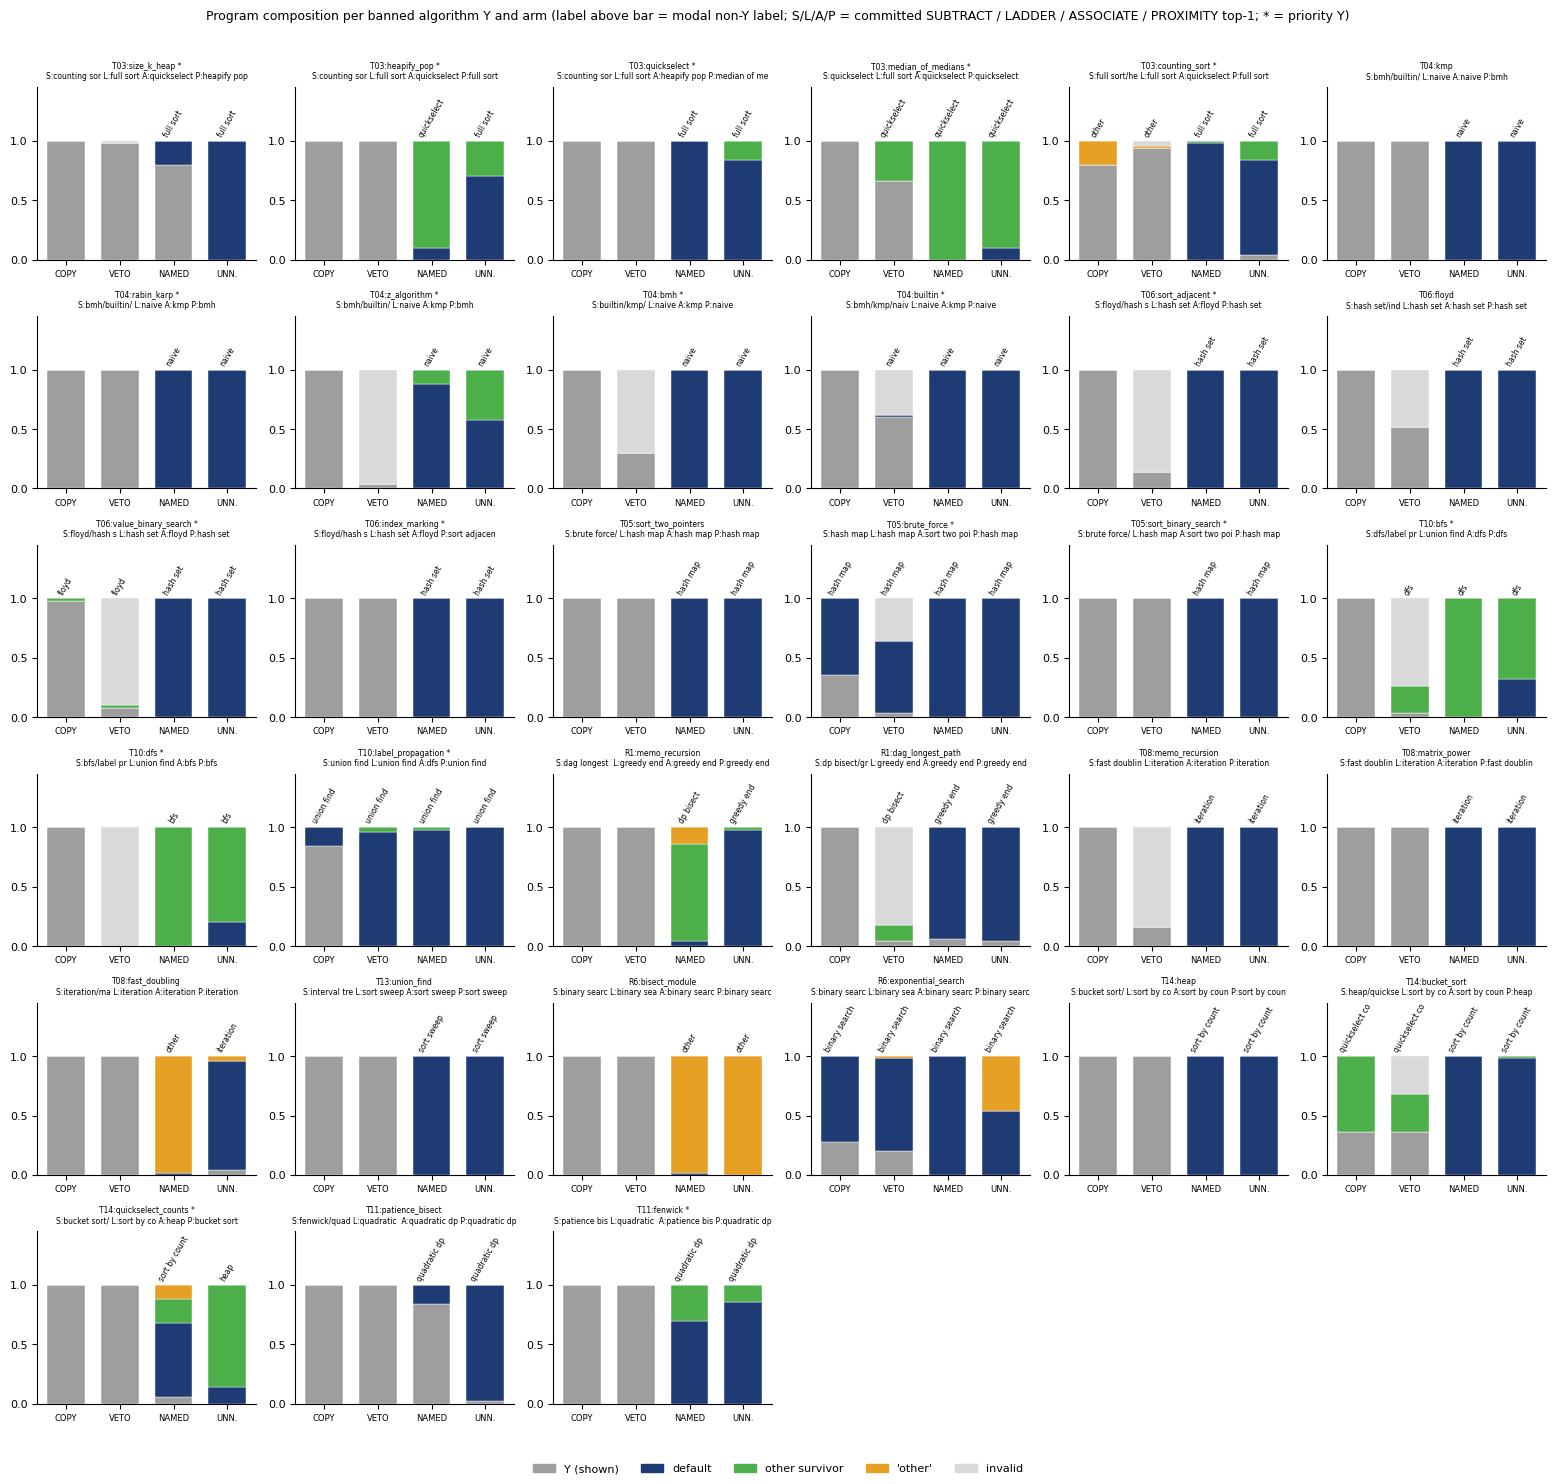

06:57:50|INFO   |figure landing_bars written


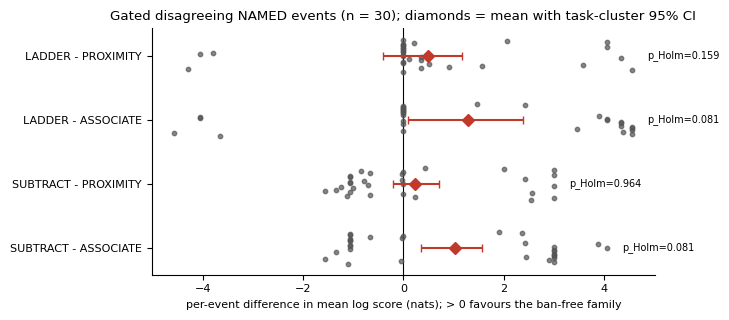

06:57:50|INFO   |figure forest_logscore_differences written


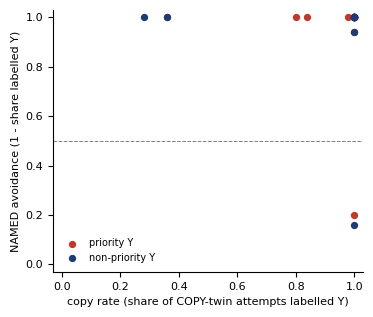

06:57:50|INFO   |figure copy_rate_vs_avoidance written


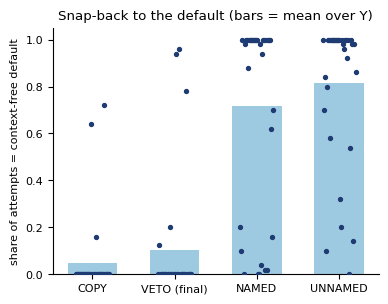

06:57:51|INFO   |figure default_share_by_arm written


In [23]:
"""Data figures (matplotlib, deterministic): landing bars per Y across arms, forest plot of per-event log-score
differences, copy rate vs avoidance, default share by arm.  PNG + PDF under figures/."""

plt.rcParams.update({"font.size": 8, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})
ROLE_COLORS = {"Y (shown)": "#9e9e9e", "default": "#1f3b73", "other survivor": "#4daf4a", "'other'": "#e6a023",
               "invalid": "#d9d9d9"}


def _save(fig, name: str) -> None:
    FIGS.mkdir(exist_ok=True)
    fig.savefig(FIGS / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")
    plt.show()  # notebook: display inline (the script called plt.close(fig))
    logger.info(f"figure {name} written")


def _short(label: str) -> str:
    return label.replace("_", " ")[:14]


def landing_bars(meta: dict, fc: dict, arms: dict) -> None:
    keys = list(meta)
    ncol = 6
    nrow = math.ceil(len(keys) / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.6 * ncol, 2.5 * nrow), squeeze=False)
    for ax, key in zip(axes.flat, keys):
        m = meta[key]
        a = arms.get(key, {})
        vr = m["veto_round_used"]
        cols = [("COPY", a.get("copy")), (f"VETO r{vr}" if vr else "VETO", a.get(f"veto_r{vr or 1}")),
                ("NAMED", a.get("named")), ("UNNAMED", a.get("unnamed"))]
        for i, (name, st) in enumerate(cols):
            if not st or not st["n_programs"]:
                continue
            n = st["n_programs"]
            lc = st["label_counts"]
            parts = {"Y (shown)": lc.get(m["Y"], 0), "default": lc.get(m["default"], 0),
                     "other survivor": sum(v for k, v in lc.items() if k in m["survivors"] and k != m["default"]),
                     "'other'": sum(v for k, v in lc.items() if k not in m["survivors"] and k not in (m["Y"], "invalid")),
                     "invalid": lc.get("invalid", 0)}
            bottom = 0.0
            for role, v in parts.items():
                ax.bar(i, v / n, bottom=bottom, color=ROLE_COLORS[role], width=0.7, edgecolor="white", linewidth=0.3)
                bottom += v / n
            mod = st.get("modal_nonY") or []
            if mod:
                ax.text(i, 1.02, _short(mod[0]), ha="center", va="bottom", fontsize=5.5, rotation=60)
        ax.set_xticks(range(4))
        ax.set_xticklabels(["COPY", "VETO", "NAMED", "UNN."], fontsize=6)
        ax.set_ylim(0, 1.45)
        ax.set_yticks([0, 0.5, 1])
        t1 = {f: c1.top1(fc[key][f], m["survivors"]) for f in c1.FAMILIES}
        ax.set_title(f"{key}{' *' if m['priority'] else ''}\n"
                     f"S:{_short('/'.join(t1['SUBTRACT']))[:12]} L:{_short(t1['LADDER'][0])[:10]} "
                     f"A:{_short('/'.join(t1['ASSOCIATE']))[:12]} P:{_short('/'.join(t1['PROXIMITY']))[:12]}",
                     fontsize=5.5)
    for ax in list(axes.flat)[len(keys):]:
        ax.axis("off")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ROLE_COLORS.values()]
    fig.legend(handles, list(ROLE_COLORS), loc="lower center", ncol=5, fontsize=8, frameon=False)
    fig.suptitle("Program composition per banned algorithm Y and arm (label above bar = modal non-Y label; "
                 "S/L/A/P = committed SUBTRACT / LADDER / ASSOCIATE / PROXIMITY top-1; * = priority Y)", fontsize=9)
    fig.tight_layout(rect=(0, 0.03, 1, 0.97))
    _save(fig, "landing_bars")


def forest(named: list[dict], res: dict) -> None:
    sel = [e for e in named if e["gate_pass"] and e["disagreeing"]]
    if not sel:
        return
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    for i, (a, b) in enumerate(c1.TEST_PAIRS):
        d = [e["logscore"][a] - e["logscore"][b] for e in sel]
        y = np.full(len(d), i) + np.linspace(-0.25, 0.25, len(d)) if len(d) > 1 else np.full(len(d), i)
        ax.scatter(d, y, s=10, color="#555555", alpha=0.7, zorder=3)
        tests = res["tests"].get("tests") if res["tests"].get("run") else None
        mean = float(np.mean(d))
        if tests:
            t = tests[i]
            ax.errorbar(mean, i, xerr=[[mean - t["ci95_task_cluster"][0]], [t["ci95_task_cluster"][1] - mean]],
                        fmt="D", color="#c0392b", capsize=3, zorder=4)
            ax.text(ax.get_xlim()[1] if False else max(d) + 0.3, i, f"p_Holm={t['p_holm']:.3f}", va="center", fontsize=7)
        else:
            ax.scatter([mean], [i], marker="D", color="#c0392b", zorder=4)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(range(len(c1.TEST_PAIRS)))
    ax.set_yticklabels([f"{a} - {b}" for a, b in c1.TEST_PAIRS])
    ax.set_xlabel("per-event difference in mean log score (nats); > 0 favours the ban-free family")
    ax.set_title(f"Gated disagreeing NAMED events (n = {len(sel)}); diamonds = mean with task-cluster 95% CI")
    _save(fig, "forest_logscore_differences")


def copy_vs_avoidance(meta: dict, arms: dict) -> None:
    xs, ys, pr = [], [], []
    for key, m in meta.items():
        a = arms.get(key, {})
        if "copy" in a and "named" in a:
            xs.append(a["copy"]["Y_share"])
            ys.append(a["named"]["avoidance"])
            pr.append(m["priority"])
    if not xs:
        return
    fig, ax = plt.subplots(figsize=(4, 3.4))
    for p, c, lab in [(True, "#c0392b", "priority Y"), (False, "#1f3b73", "non-priority Y")]:
        ax.scatter([x for x, q in zip(xs, pr) if q == p], [y for y, q in zip(ys, pr) if q == p], s=18, color=c, label=lab)
    ax.axhline(0.5, color="gray", lw=0.7, ls="--")
    ax.set_xlabel("copy rate (share of COPY-twin attempts labelled Y)")
    ax.set_ylabel("NAMED avoidance (1 - share labelled Y)")
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)
    ax.legend(frameon=False, fontsize=7)
    _save(fig, "copy_rate_vs_avoidance")


def default_share(meta: dict, arms: dict) -> None:
    cols = ["copy", "veto_final", "named", "unnamed"]
    vals = {c: [] for c in cols}
    for key, m in meta.items():
        a = arms.get(key, {})
        vk = sorted(k for k in a if k.startswith("veto_r"))
        mp = {"copy": a.get("copy"), "veto_final": a.get(vk[-1]) if vk else None, "named": a.get("named"),
              "unnamed": a.get("unnamed")}
        for c in cols:
            if mp[c] and mp[c]["n_attempts"]:
                vals[c].append(mp[c]["default_share"])
    fig, ax = plt.subplots(figsize=(4.2, 3.2))
    for i, c in enumerate(cols):
        v = vals[c]
        if not v:
            continue
        ax.bar(i, np.mean(v), color="#9ecae1", width=0.6)
        ax.scatter(np.full(len(v), i) + np.linspace(-0.2, 0.2, len(v)), v, s=8, color="#1f3b73", zorder=3)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(["COPY", "VETO (final)", "NAMED", "UNNAMED"])
    ax.set_ylabel("share of attempts = context-free default")
    ax.set_title("Snap-back to the default (bars = mean over Y)")
    _save(fig, "default_share_by_arm")


def make_figures(samples, meta, fc, arms, named, res_named) -> None:
    landing_bars(meta, fc, arms)
    forest(named, res_named)
    copy_vs_avoidance(meta, arms)
    default_share(meta, arms)


make_figures(None, meta, fc, arms, named, res_named)  # samples is not used by the figures

## 13 · Key results

One row per banned algorithm Y (`*` = priority Y):

- **copy** — the share of COPY attempts that use Y;
- **avoid** — NAMED avoidance;
- **default share** — the share of attempts that use the default, in each arm;
- **NAMED modal** — the most common NAMED replacement;
- **C1 winner** — the family with a ≥ 0.10-nat margin, if any;
- **committed top-1** — each family's top-1 (S | L | A | P = SUBTRACT, LADDER, ASSOCIATE, PROXIMITY).

The three panels below the table show:

- **(a)** the default's share in each arm;
- **(b)** how often each family's top-1 names the replacement;
- **(c)** the per-event log scores that decide the frozen contest.

task:Y                    pri  copy avoid   default share: COPY  VETO NAMED  UNN.   NAMED modal      C1 winner   committed top-1  S | L | A | P
T03:size_k_heap             *  1.00  0.20                  0.00  0.00  0.20  1.00   full_sort        (no gate)   uniform | full_sort | quickselect | heapify_pop
T03:heapify_pop             *  1.00  1.00                  0.00  0.12  0.10  0.70   quickselect      ASSOCIATE   uniform | full_sort | quickselect | full_sort
T03:quickselect             *  1.00  1.00                  0.00  0.00  1.00  0.84   full_sort        LADDER      uniform | full_sort | heapify_pop | median_of_medians
T03:median_of_medians       *  1.00  1.00                  0.00  0.00  0.00  0.10   quickselect      -           quickselect | full_sort | quickselect | quickselect
T03:counting_sort           *  0.80  1.00                  0.00  0.00  0.98  0.80   full_sort        LADDER      uniform | full_sort | quickselect | full_sort
T04:kmp                        1.00  1.00    

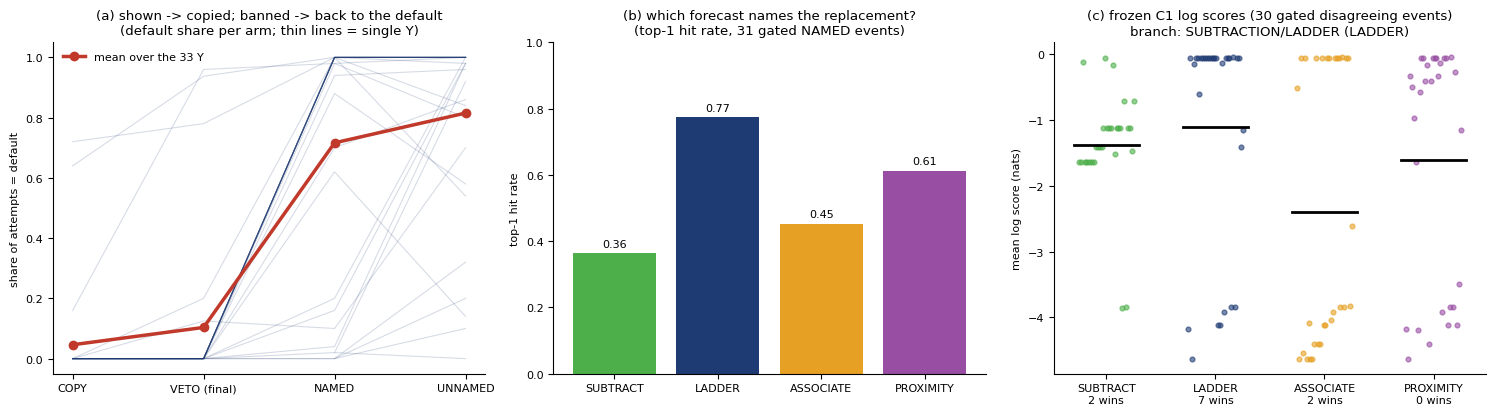

In [24]:
# ---- key results: one row per banned algorithm Y, then three summary panels ----
win_of = {(e["task"], e["Y"]): w for e, w in zip([e for e in named if e["gate_pass"] and e["disagreeing"]],
                                                  res_named["rule"]["winners"])}
print(f"{'task:Y':<26}{'pri':>3}{'copy':>6}{'avoid':>6}   default share: COPY  VETO NAMED  UNN.   "
      f"{'NAMED modal':<17}{'C1 winner':<10}  committed top-1  S | L | A | P")
for e in named:
    key = f"{e['task']}:{e['Y']}"
    ds = rep["default_share_by_arm"][key]
    t1 = e["top1"]
    winner = win_of.get((e["task"], e["Y"]), "-") if e["gate_pass"] else "(no gate)"
    f2 = lambda x: f"{x:4.2f}" if _finite(x) else "   -"
    print(f"{key:<26}{'*' if e['priority'] else '':>3}{arms[key]['copy']['Y_share']:>6.2f}{e['avoidance']:>6.2f}"
          f"                  {f2(ds['copy'])}  {f2(ds['veto_final'])}  {f2(ds['named'])}  {f2(ds['unnamed'])}   "
          f"{'/'.join(e['modal'])[:16]:<17}{winner or '-':<10}  "
          f"{'uniform' if len(t1['SUBTRACT']) > 1 else t1['SUBTRACT'][0]} | {'/'.join(t1['LADDER'])} | "
          f"{'/'.join(t1['ASSOCIATE'])} | {'/'.join(t1['PROXIMITY'])}")

fam_colors = {"SUBTRACT": "#4daf4a", "LADDER": "#1f3b73", "ASSOCIATE": "#e6a023", "PROXIMITY": "#984ea3"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax = axes[0]
for ds in rep["default_share_by_arm"].values():
    ax.plot(range(4), [ds.get(k, np.nan) for k in ARM_ORDER], color="#1f3b73", alpha=0.18, lw=0.8)
ax.plot(range(4), [mean_default[k] for k in ARM_ORDER], color="#c0392b", lw=2.5, marker="o", label="mean over the 33 Y")
ax.set_xticks(range(4), ["COPY", "VETO (final)", "NAMED", "UNNAMED"])
ax.set_ylabel("share of attempts = default")
ax.set_title("(a) shown -> copied; banned -> back to the default\n(default share per arm; thin lines = single Y)")
ax.legend(frameon=False)
ax = axes[1]
ax.bar(range(4), [hits[f] for f in c1.FAMILIES], color=[fam_colors[f] for f in c1.FAMILIES])
for i, f in enumerate(c1.FAMILIES):
    ax.text(i, hits[f] + 0.02, f"{hits[f]:.2f}", ha="center")
ax.set_xticks(range(4), c1.FAMILIES)
ax.set_ylim(0, 1)
ax.set_ylabel("top-1 hit rate")
ax.set_title(f"(b) which forecast names the replacement?\n(top-1 hit rate, {len(gated)} gated NAMED events)")
ax = axes[2]
sel = [e for e in named if e["gate_pass"] and e["disagreeing"]]
for i, f in enumerate(c1.FAMILIES):
    v = [e["logscore"][f] for e in sel]
    ax.scatter(np.full(len(v), i) + np.linspace(-0.25, 0.25, len(v)), v, s=12, alpha=0.6, color=fam_colors[f])
    ax.plot([i - 0.3, i + 0.3], [np.mean(v)] * 2, color="black", lw=2)
ax.set_xticks(range(4), [f"{f}\n{res_named['rule']['wins'][f]} wins" for f in c1.FAMILIES])
ax.set_ylabel("mean log score (nats)")
ax.set_title(f"(c) frozen C1 log scores ({len(sel)} gated disagreeing events)\nbranch: {res_named['branch']}")
plt.tight_layout()
plt.show()

## What the numbers say

- **Showing a solution makes the model copy it.** Under COPY, a mean 93% of attempts use the shown algorithm (median 100%); the default appears in only ~5% of them. Context moves the model far from its default.
- **The ban is obeyed, and the replacement snaps back to the default.** Avoidance is 0.95 (NAMED) and 0.996 (UNNAMED). The default's share of attempts rises from 0.05 (COPY) to 0.10 (final veto round), 0.72 (NAMED) and 0.82 (UNNAMED). NAMED and UNNAMED pick the same modal replacement for 88% of Y, so naming Y adds little beyond "something else".
- **Frozen verdict: `SUBTRACTION/LADDER (LADDER)`.** On the gated disagreeing NAMED events, LADDER wins 7, SUBTRACT 2, ASSOCIATE 2 and PROXIMITY 0. LADDER names the replacement in 77% of the gated events; ASSOCIATE does in 45%.
- **Read the verdict with its caveats:**
  - No NAMED test survives Holm.
  - The ≥ 3-wins rule advances some family in 100% of the label-permutation placebo draws, so the branch label alone is weak evidence.
  - The paired tests and CIs are the informative part, and they consistently rank LADDER and SUBTRACT above ASSOCIATE.
  - The signature veto rarely removed Y: SUBTRACT is defined for only 4 of 33 Y, because the algorithm survives the removal of its surface tokens.

**Bottom line.** On Qwen3-8B, banning a just-shown algorithm sends the model back to its context-free default far more often than to its own stated "standard alternative". This experiment gives no support to a substitution account. A shown solution pulls the model into a different region of the solution space, but a prohibition does not move it to a neighbouring region: it falls back to its default answer.